In [1]:
import ROOT as r
import matplotlib.pyplot as plt
import numpy as np
import pickle
import uproot
import array

Welcome to JupyROOT 6.30/02


## Load latest version of fits and cross sections

In [2]:
fFit = r.TFile.Open("/nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/asimov_fit.root", "READ")
fXsec = r.TFile.Open("/nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/nue_asimovXSec.root", "READ")

fPreError = r.TFile.Open("/nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/asimov_toy_prefit.root", "READ")
fPostError = r.TFile.Open("/nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/asimov_toy_bf.root", "READ")

OSError: Failed to open file /nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/asimov_fit.root

Error in <TFile::TFile>: file /nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/asimov_fit.root does not exist


### Plot Covariance

Info in <TCanvas::Print>: png file /nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/covarianceMatrix.png has been created


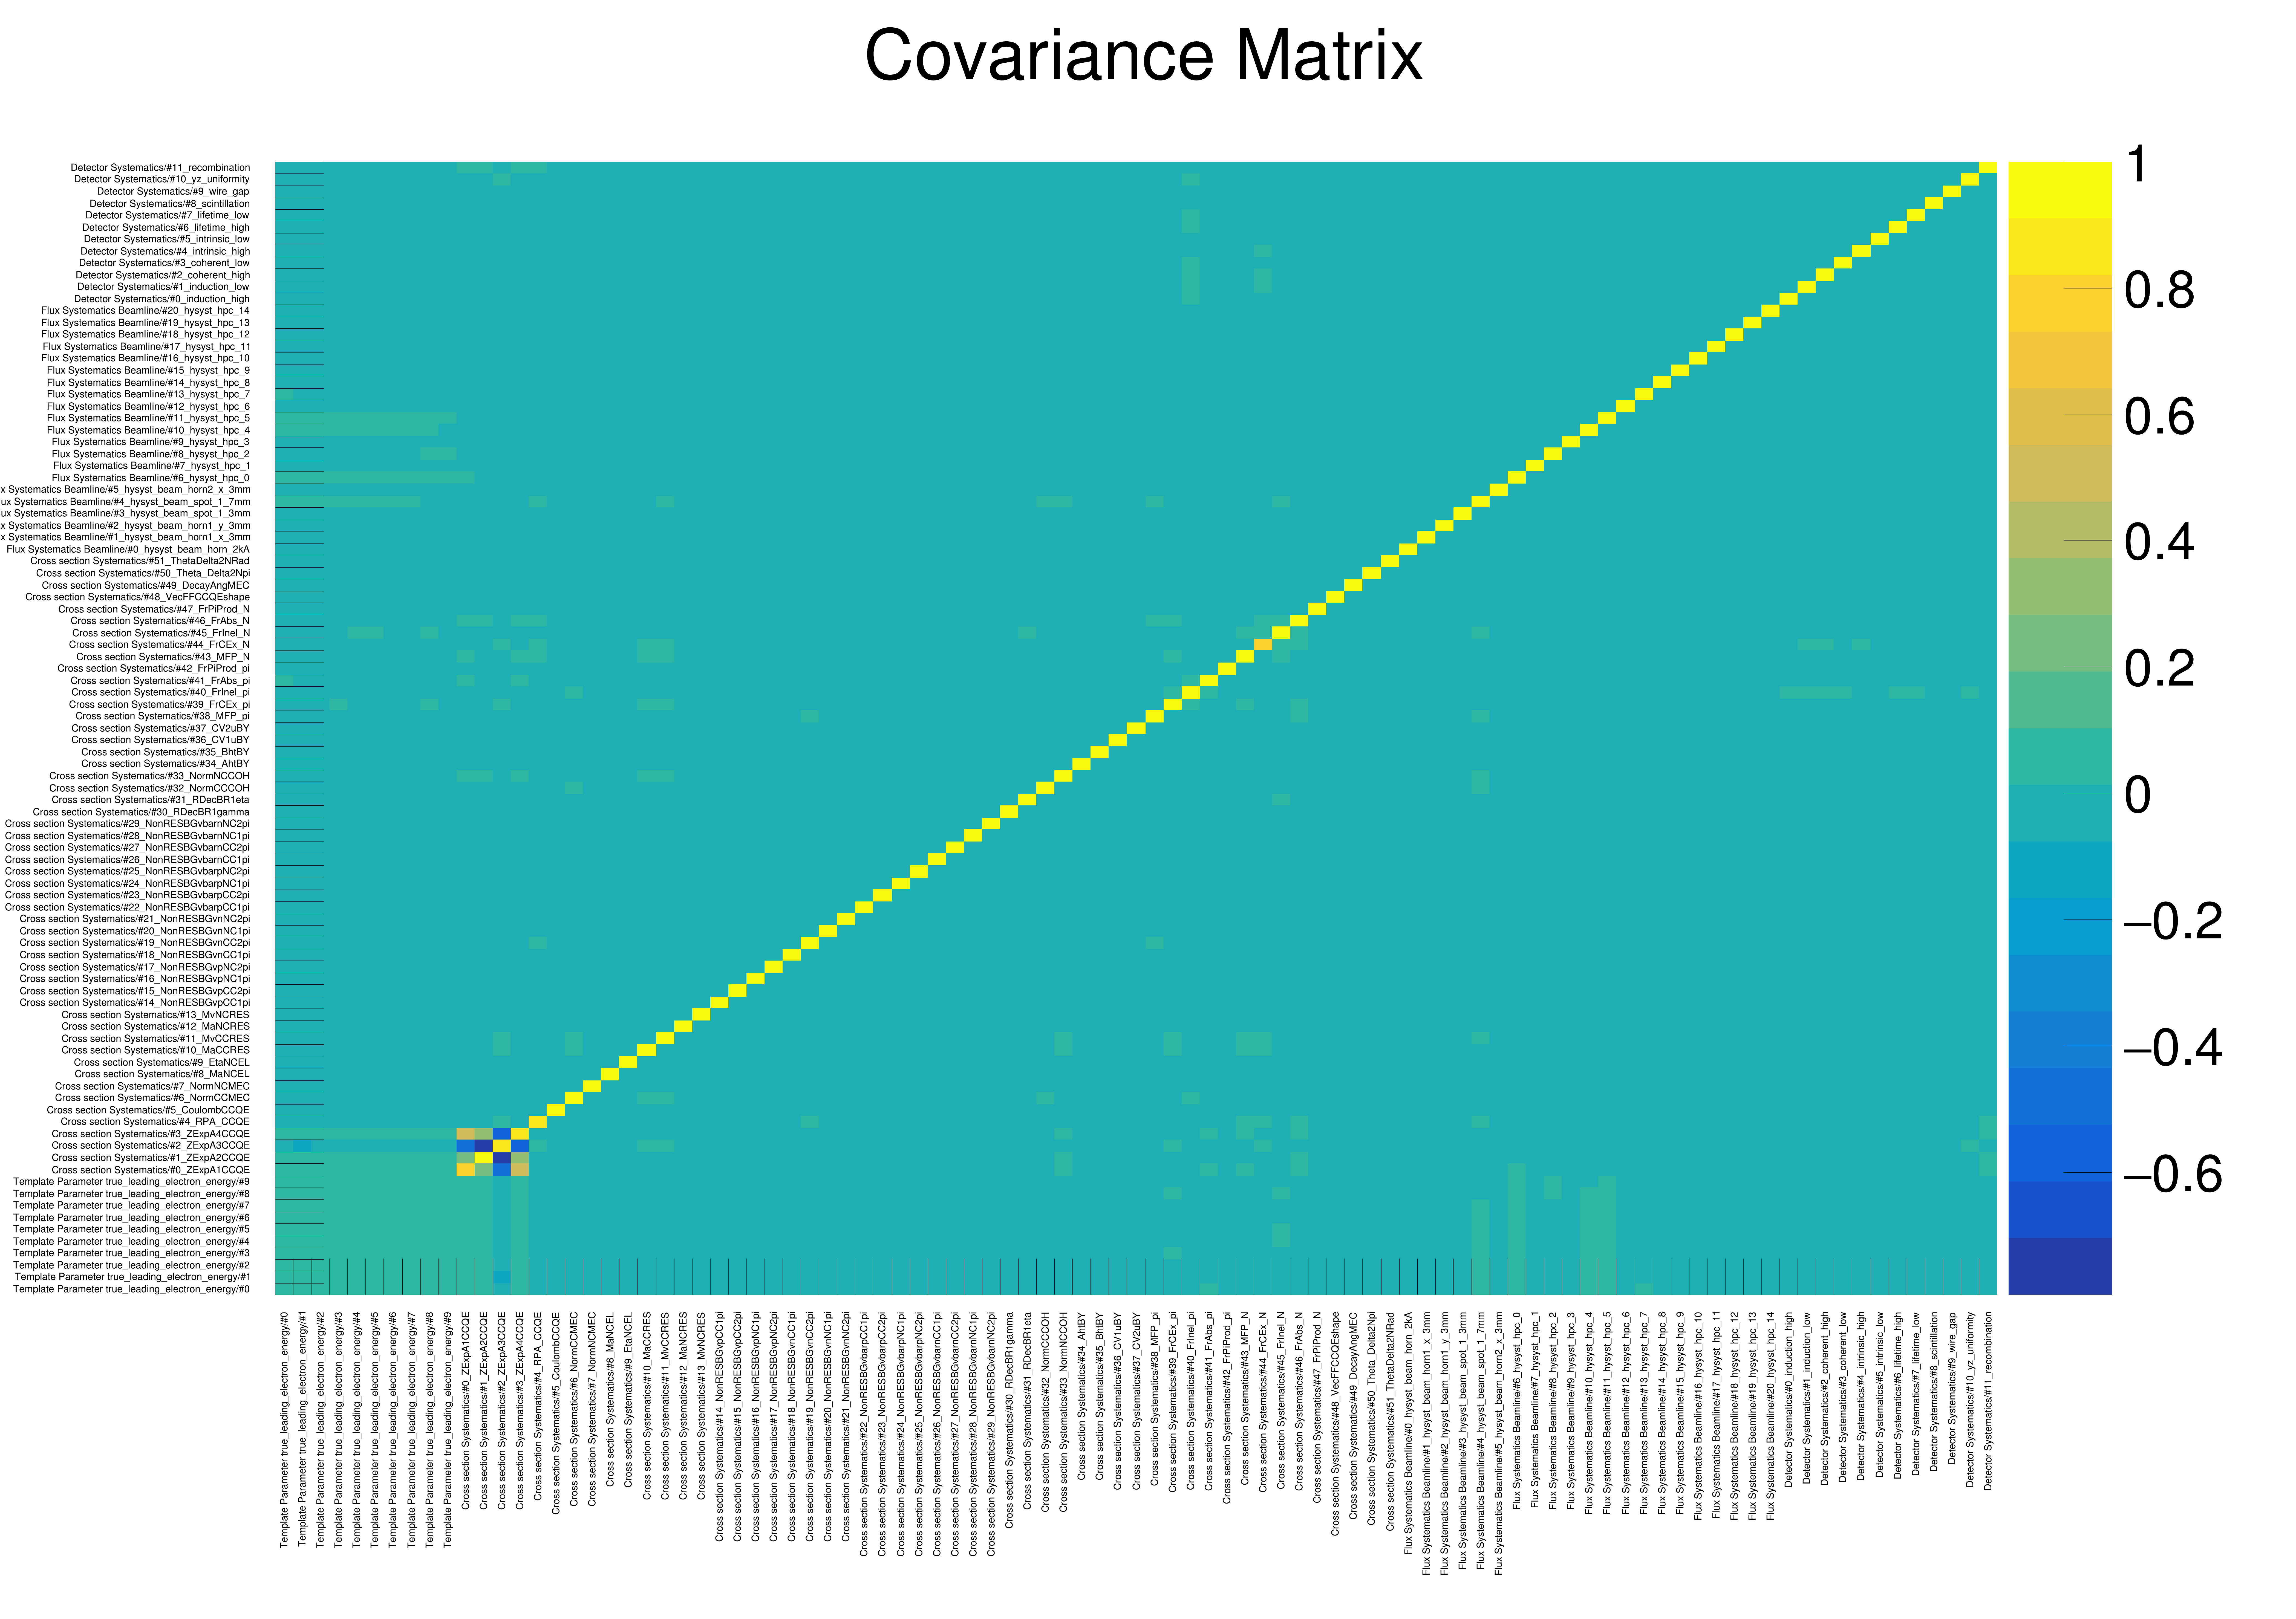

In [6]:
c = r.TCanvas("c", "c", 2800, 2000)
h_cov = fFit.Get("FitterEngine/postFit/Hesse/hessian/postfitCovariance_TH2D")

r.gStyle.SetPalette(r.kBird)

h_cov.SetTitle("Covariance Matrix;;")
# h_cov.GetZaxis().SetRangeUser(-10, 10)
h_cov.GetXaxis().SetLabelSize(0.01)
h_cov.GetYaxis().SetLabelSize(0.01)
h_cov.Draw("COLZ")
# c.SetLogz()
c.SetLeftMargin(0.12)
c.SetBottomMargin(0.2)
c.SetRightMargin(0.13)
c.Draw()
r.gStyle.SetImageScaling(3.)
c.SaveAs("/nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/covarianceMatrix.png")


### Plot Correlation

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c
Info in <TCanvas::Print>: png file /nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/correlationMatrix.png has been created


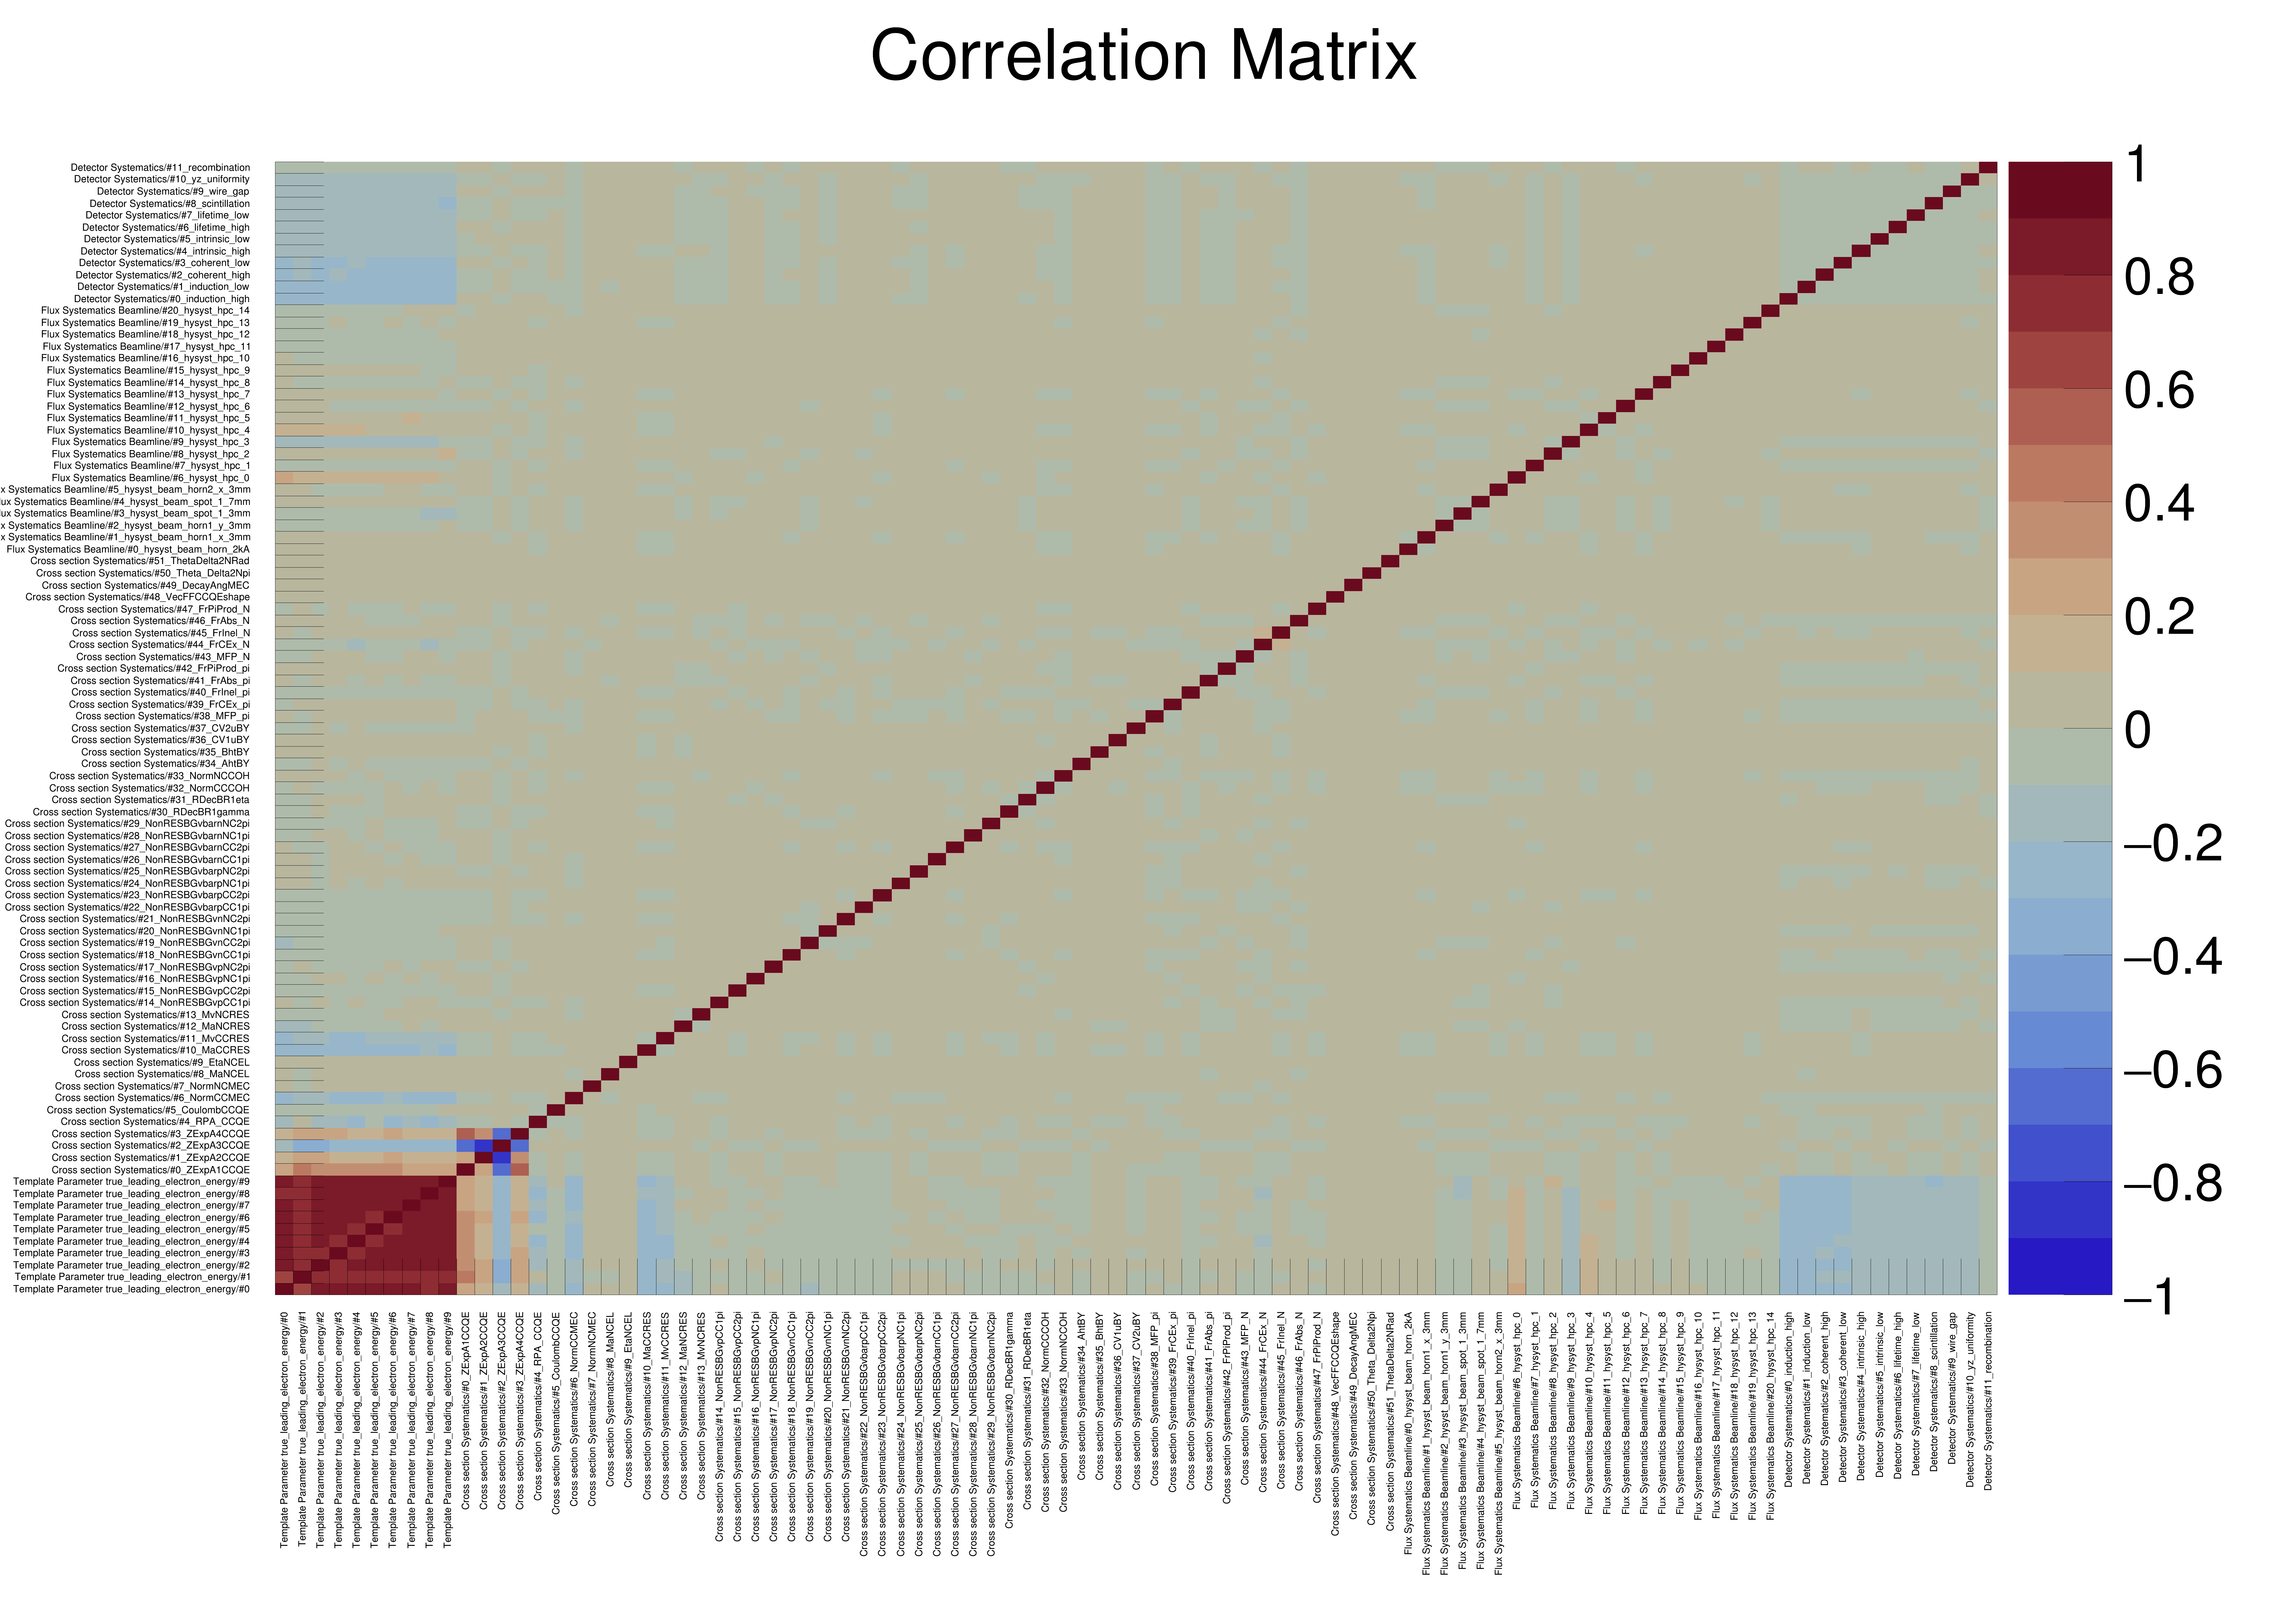

In [7]:
c = r.TCanvas("c", "c", 2800, 2000)
h_cor = fFit.Get("FitterEngine/postFit/Hesse/hessian/postfitCorrelation_TH2D")

r.gStyle.SetPalette(r.kThermometer)

h_cor.SetTitle("Correlation Matrix;;")
h_cor.GetZaxis().SetRangeUser(-1, 1)
h_cor.GetXaxis().SetLabelSize(0.01)
h_cor.GetYaxis().SetLabelSize(0.01)
h_cor.GetXaxis().LabelsOption("v")
h_cor.Draw("COLZ")
# c.SetLogz()
c.SetLeftMargin(0.12)
c.SetBottomMargin(0.2)
c.SetRightMargin(0.13)
c.SaveAs("/nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/correlationMatrix.png")
c.Draw()


### Plot pre/post fits

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c
Info in <TCanvas::Print>: png file /nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/TemplateParameters.png has been created


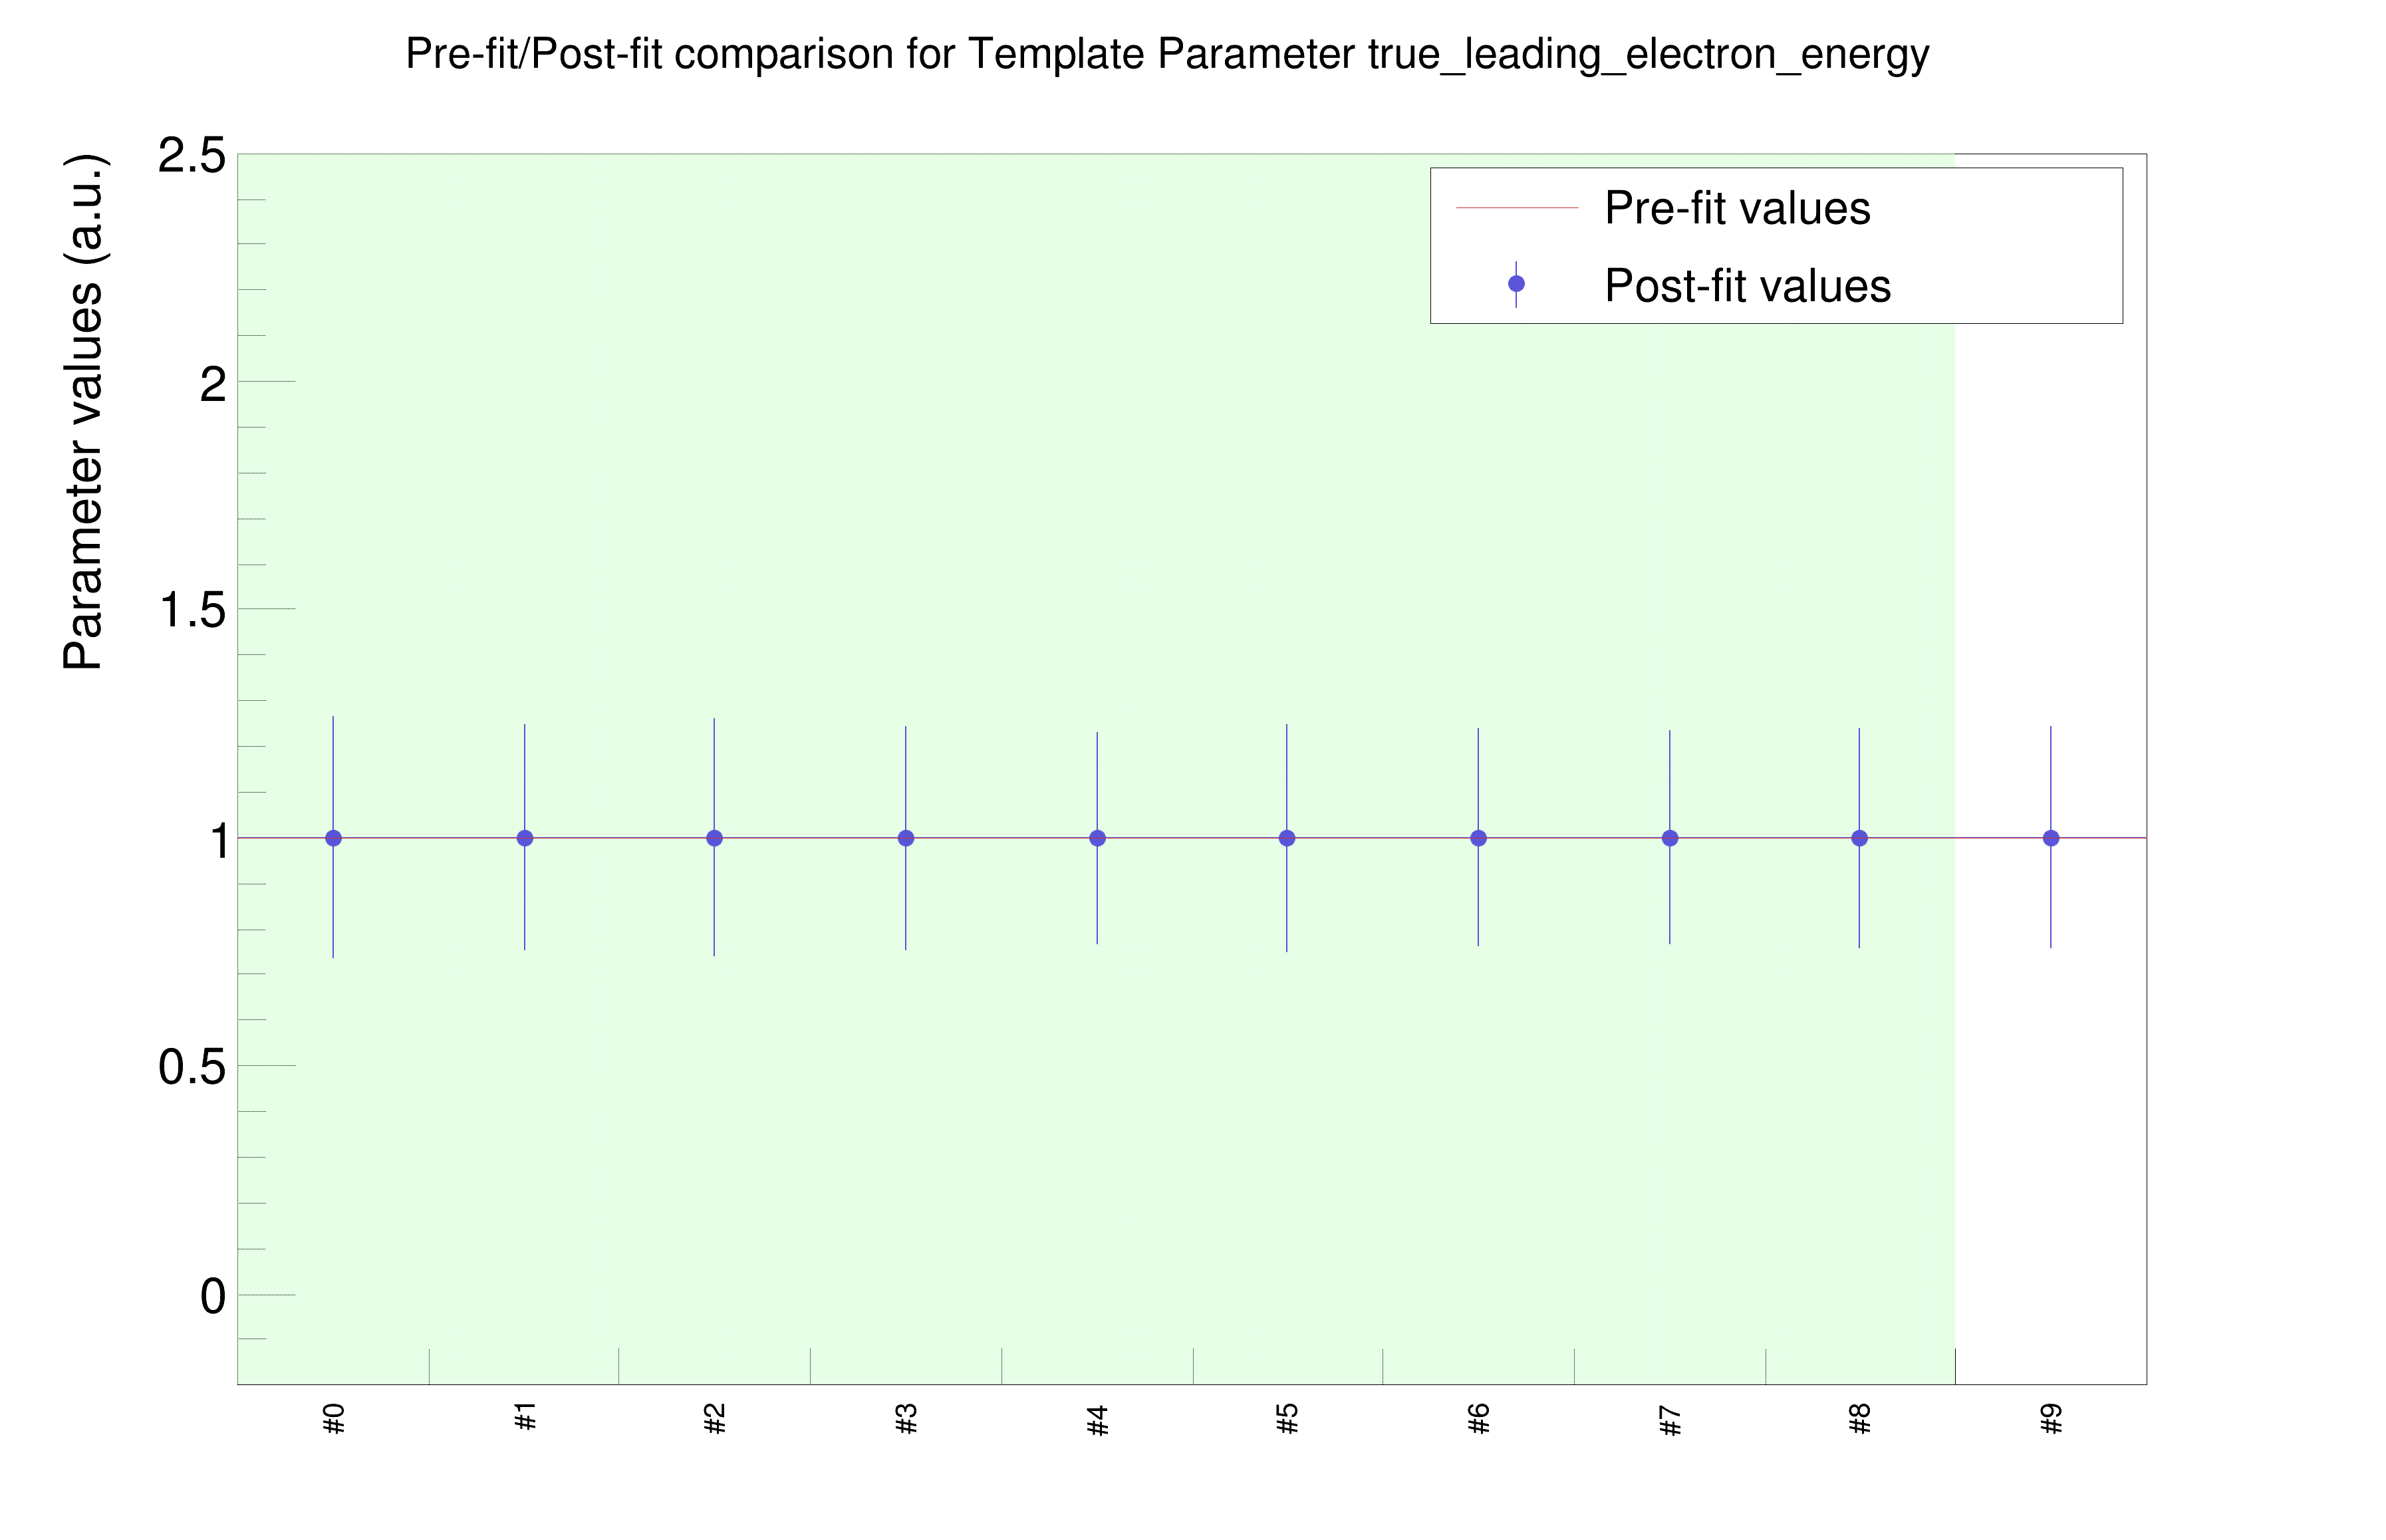

In [ ]:
# this plot is drawn in the wrong order for some reason and so it needs to be completely redrawn by hand

c_par = fFit.Get("FitterEngine/postFit/Hesse/errors/Template Parameter true_leading_electron_energy/values/fitConstraints_TCanvas")

primitives = list(c_par.GetListOfPrimitives())  # make a Python list copy

# Identify your objects by name or type
h_prefit = c_par.GetPrimitive("preFitErrors")
h_postfit = c_par.GetPrimitive("postFitErrors")
h_line = c_par.GetPrimitive("preFitErrorHistLine")
tpave = c_par.GetPrimitive("TPave")  # or get by index/type

# Clone all objects BEFORE drawing
objects_to_draw = []

if h_prefit:
    objects_to_draw.append(h_prefit.Clone())
if h_postfit:
    objects_to_draw.append(h_postfit.Clone())
if h_line:
    objects_to_draw.append(h_line.Clone())
if tpave:
    objects_to_draw.append(tpave.Clone())

for i in range(2, 12):
    objects_to_draw.append(primitives[i].Clone())

# Now create a new canvas
c = r.TCanvas("c", "c", 1200, 800)

h_prefit.Draw()

# Draw the objects in the correct order
for i, obj in enumerate(objects_to_draw[::-1]):
    obj.Draw("same")


c.Modified()
c.Draw()
c.SaveAs("/nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/TemplateParameters.png")

Info in <TCanvas::Print>: png file /nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/TemplateParametersCovariance.png has been created


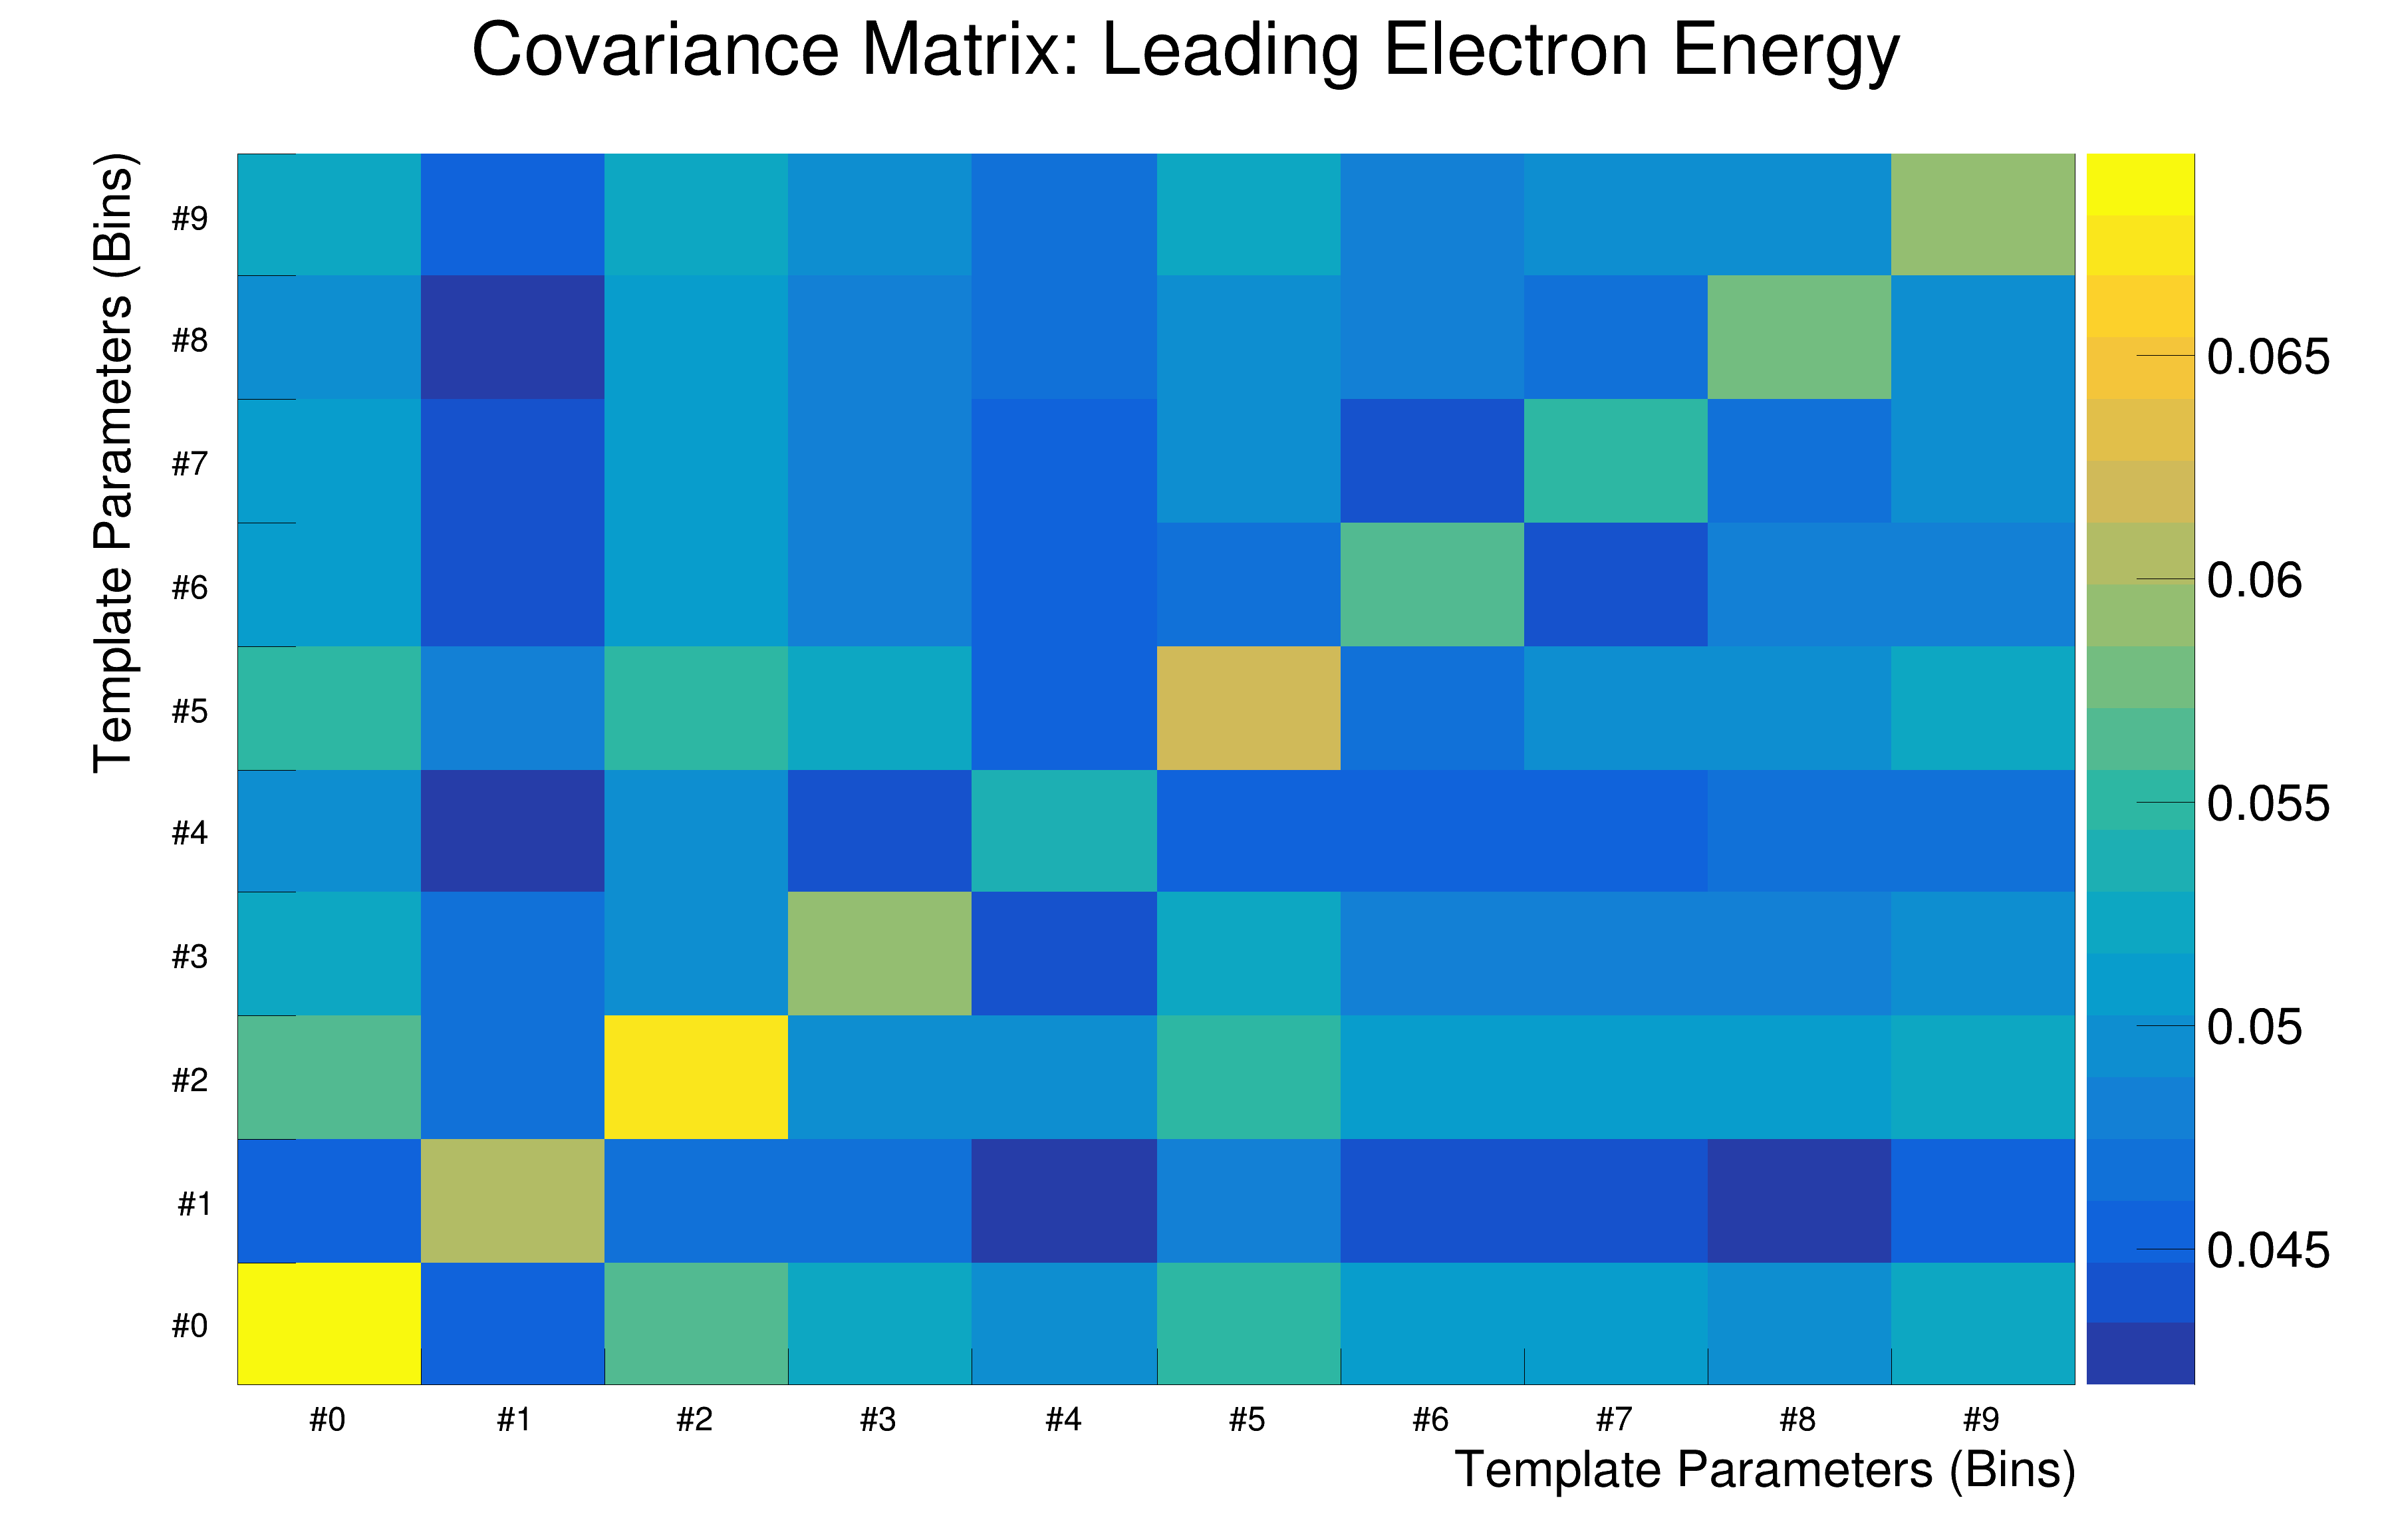

In [9]:
c1 = r.TCanvas("c1", "c1", 1200, 800)

h_cov = fFit.Get("FitterEngine/postFit/Hesse/errors/Template Parameter true_leading_electron_energy/matrices/Covariance_TH2D")
r.gStyle.SetPalette(r.kBird)

h_cov.Draw("colz")
h_cov.SetTitle("Covariance Matrix: Leading Electron Energy;Template Parameters (Bins);Template Parameters (Bins)")
c1.SetRightMargin(0.13)
c1.Draw()

c1.SaveAs("/nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/TemplateParametersCovariance.png")

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: png file /nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/TemplateParametersCorrelation.png has been created


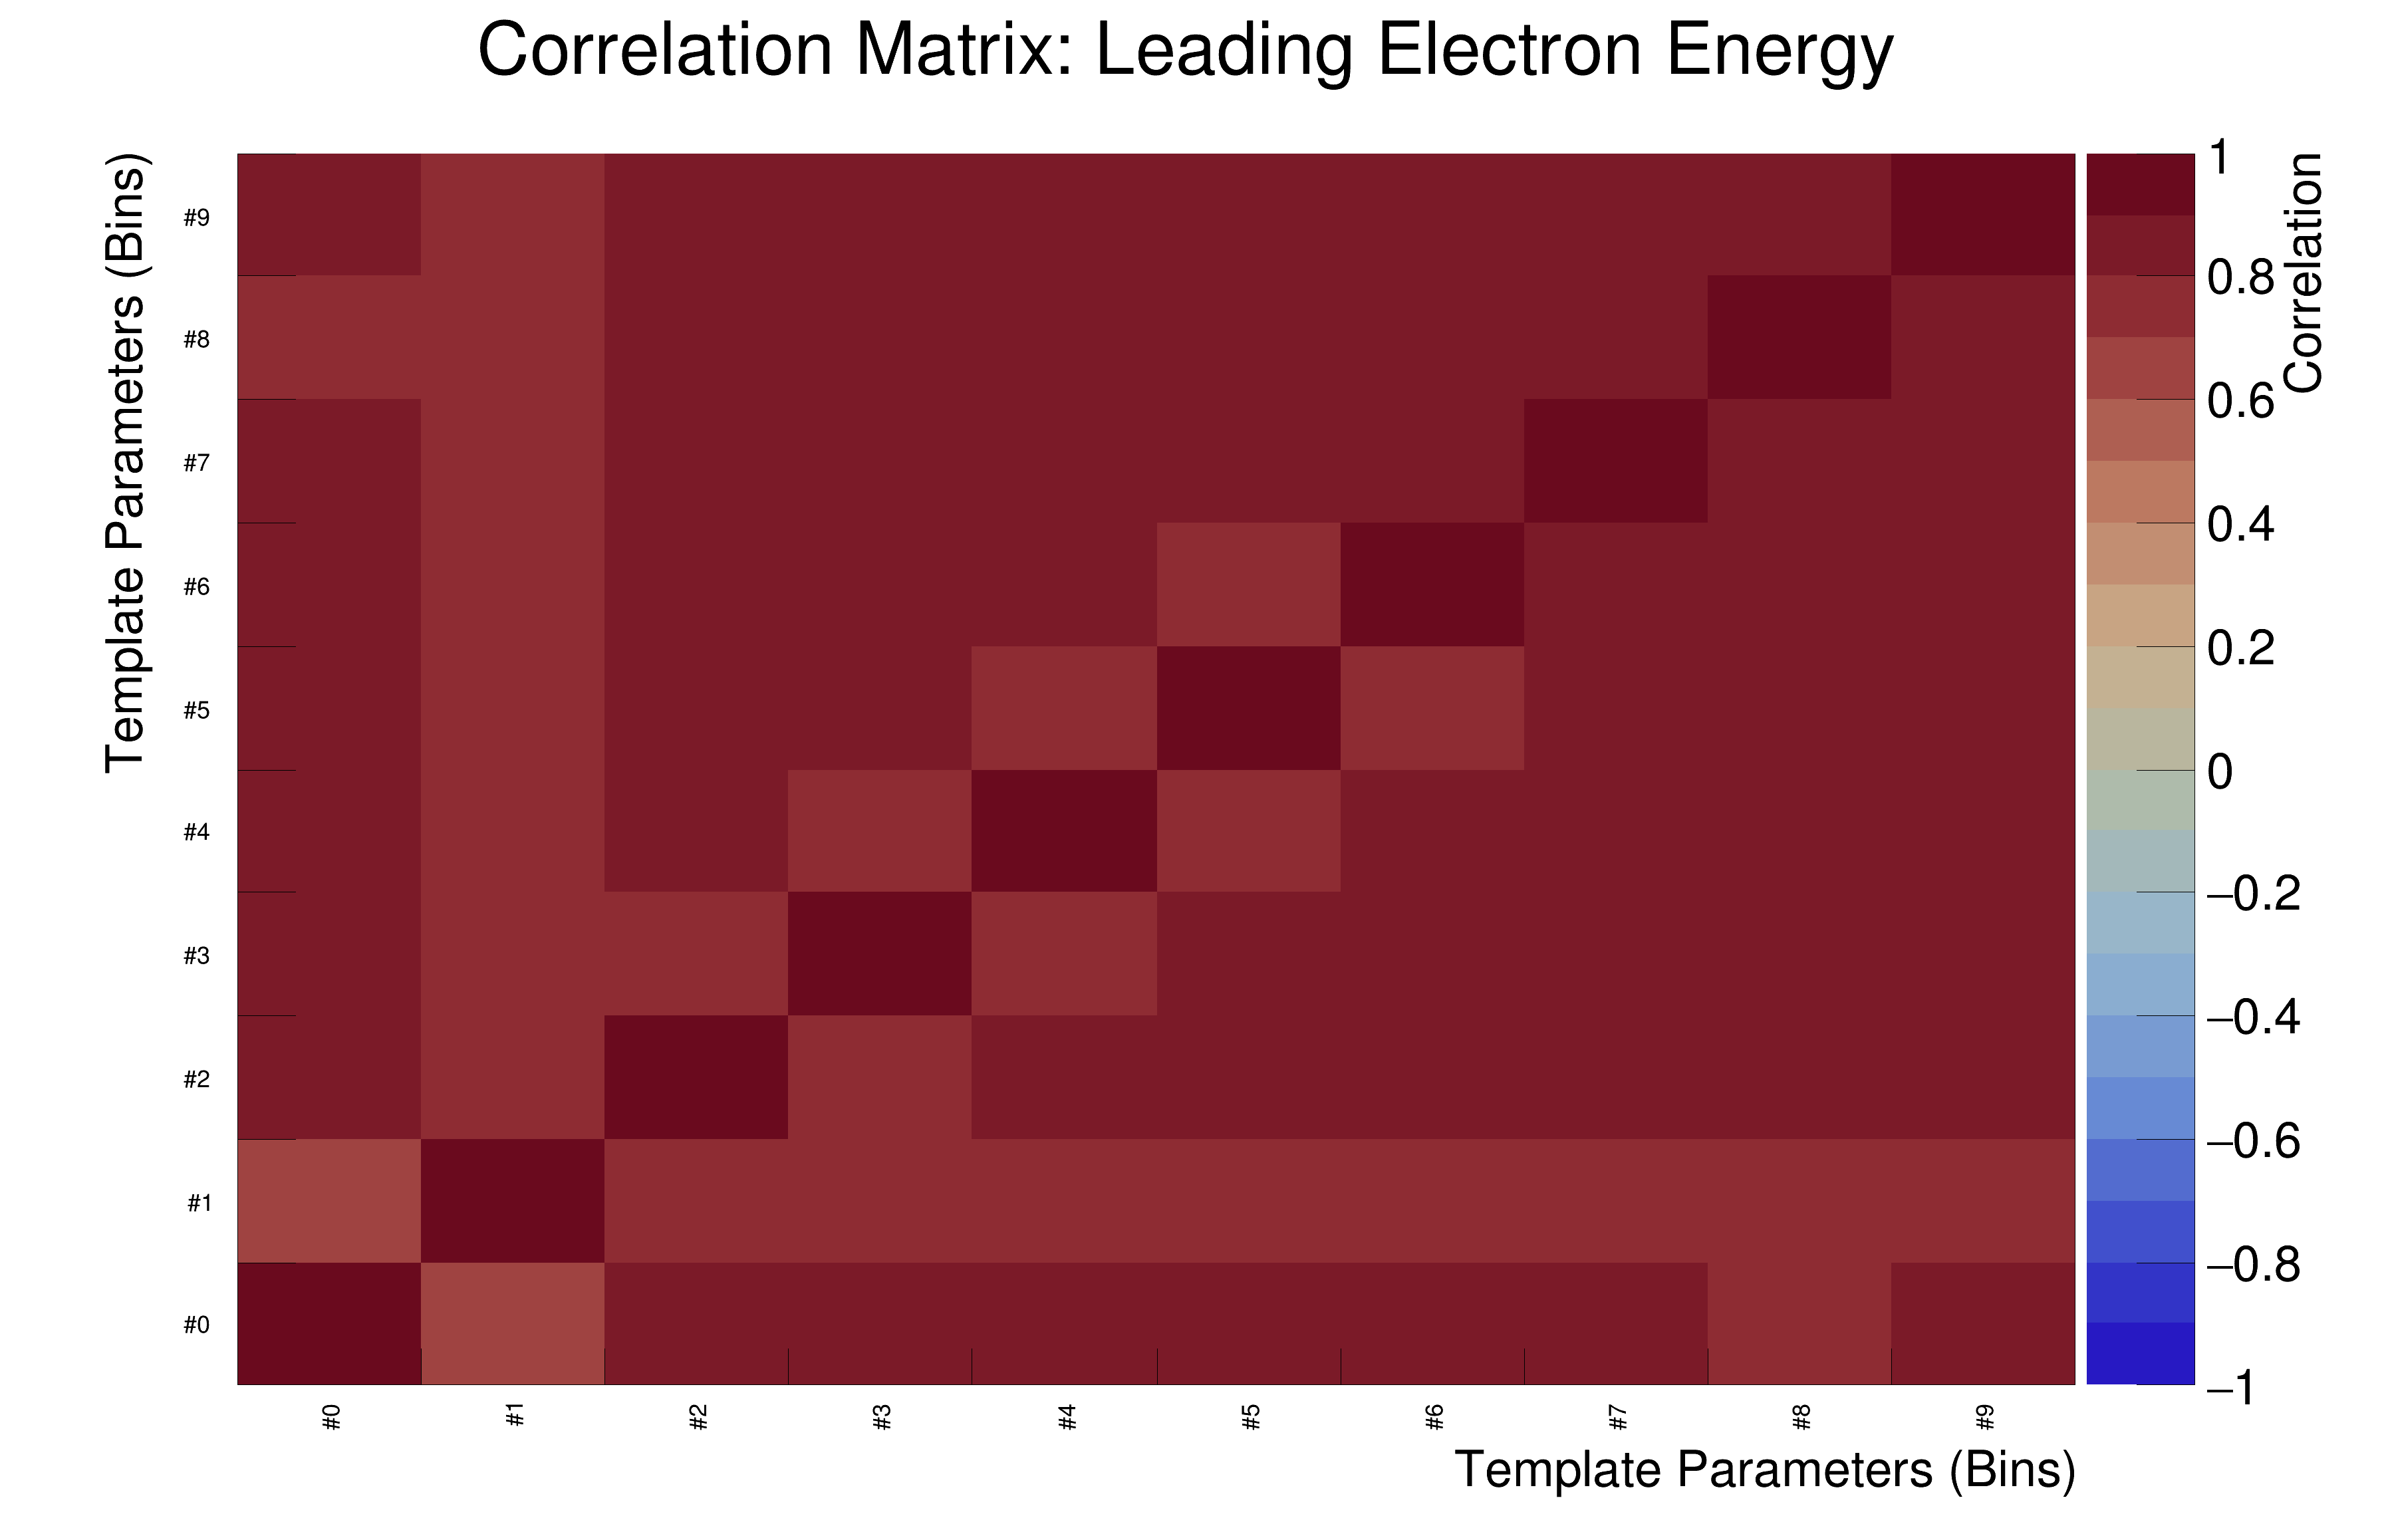

In [10]:
c1 = r.TCanvas("c1", "c1", 1200, 800)

h_cov = fFit.Get("FitterEngine/postFit/Hesse/errors/Template Parameter true_leading_electron_energy/matrices/Correlation_TH2D")
r.gStyle.SetPalette(r.kThermometer)

h_cov.Draw("colz")
h_cov.SetTitle("Correlation Matrix: Leading Electron Energy;Template Parameters (Bins);Template Parameters (Bins)")
c1.SetRightMargin(0.13)
c1.Draw()

c1.SaveAs("/nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/TemplateParametersCorrelation.png")

Info in <TCanvas::Print>: png file /nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/XSecConstraints.png has been created


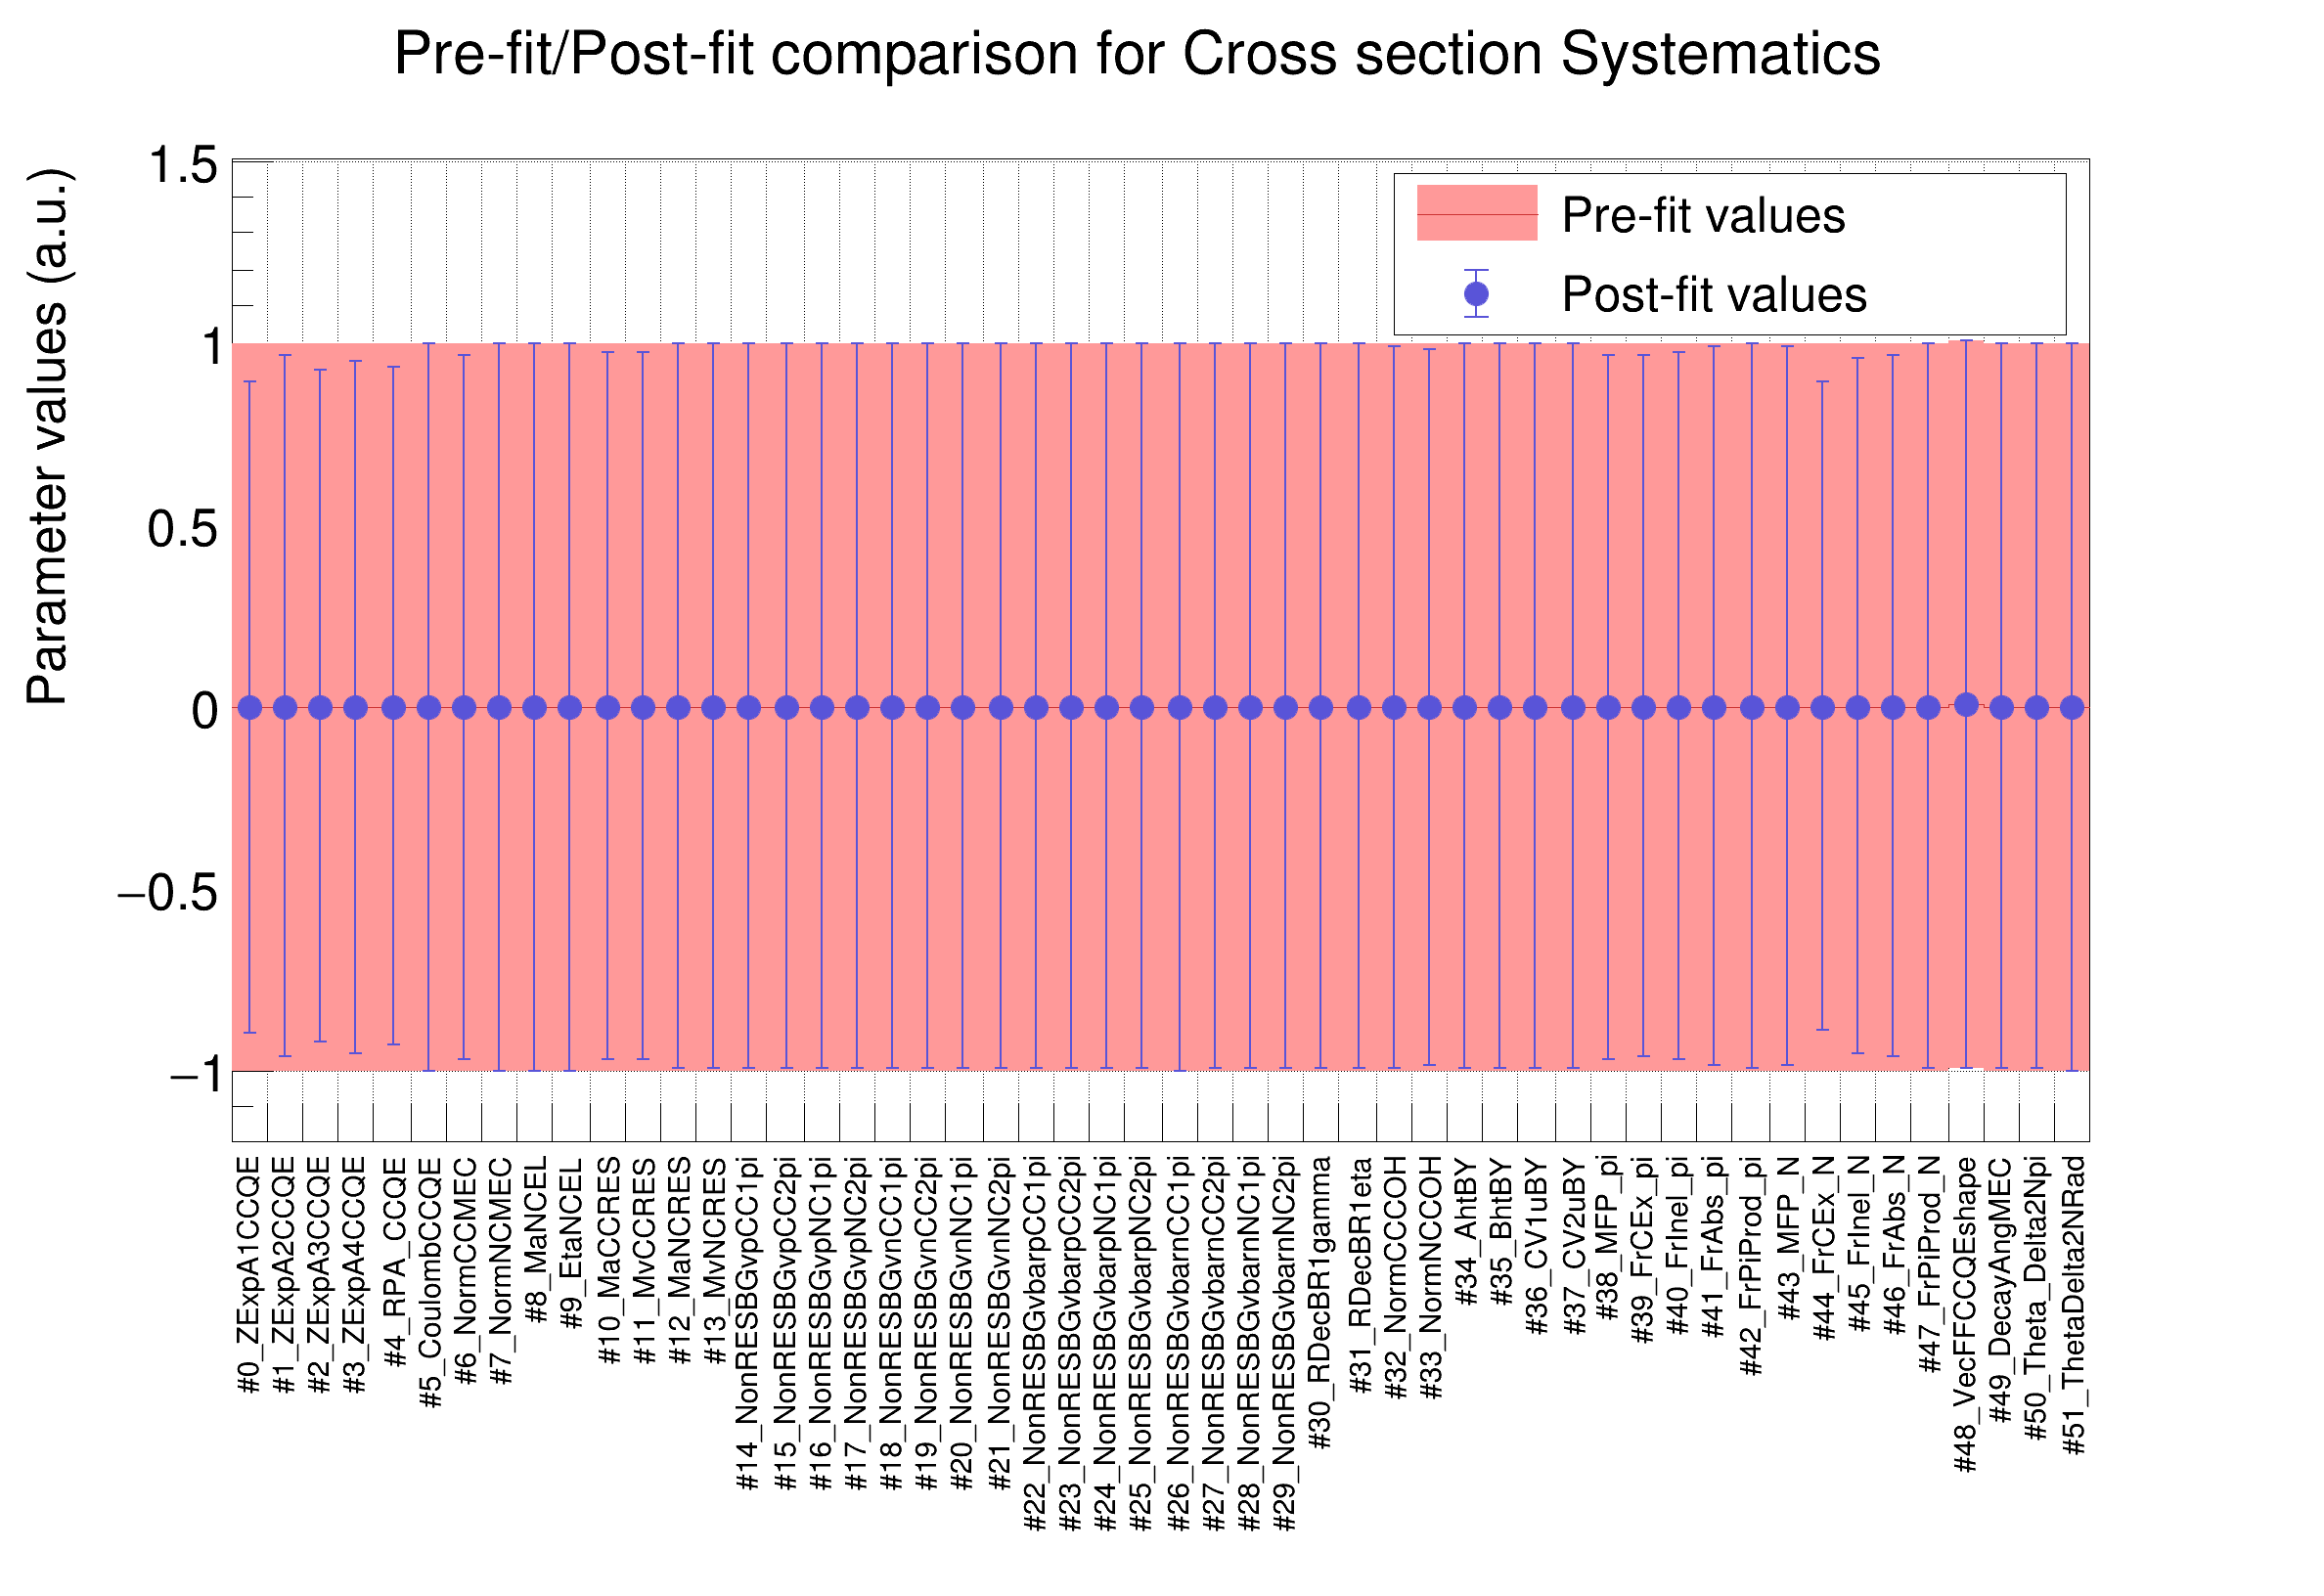

In [11]:
c_par = fFit.Get("FitterEngine/postFit/Hesse/errors/Cross section Systematics/values/fitConstraints_TCanvas")

c_par.SetCanvasSize(2000, 1200)
c_par.Draw()

c_par.SaveAs("/nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/XSecConstraints.png")


Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: png file /nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/CrossSectionCovariance.png has been created


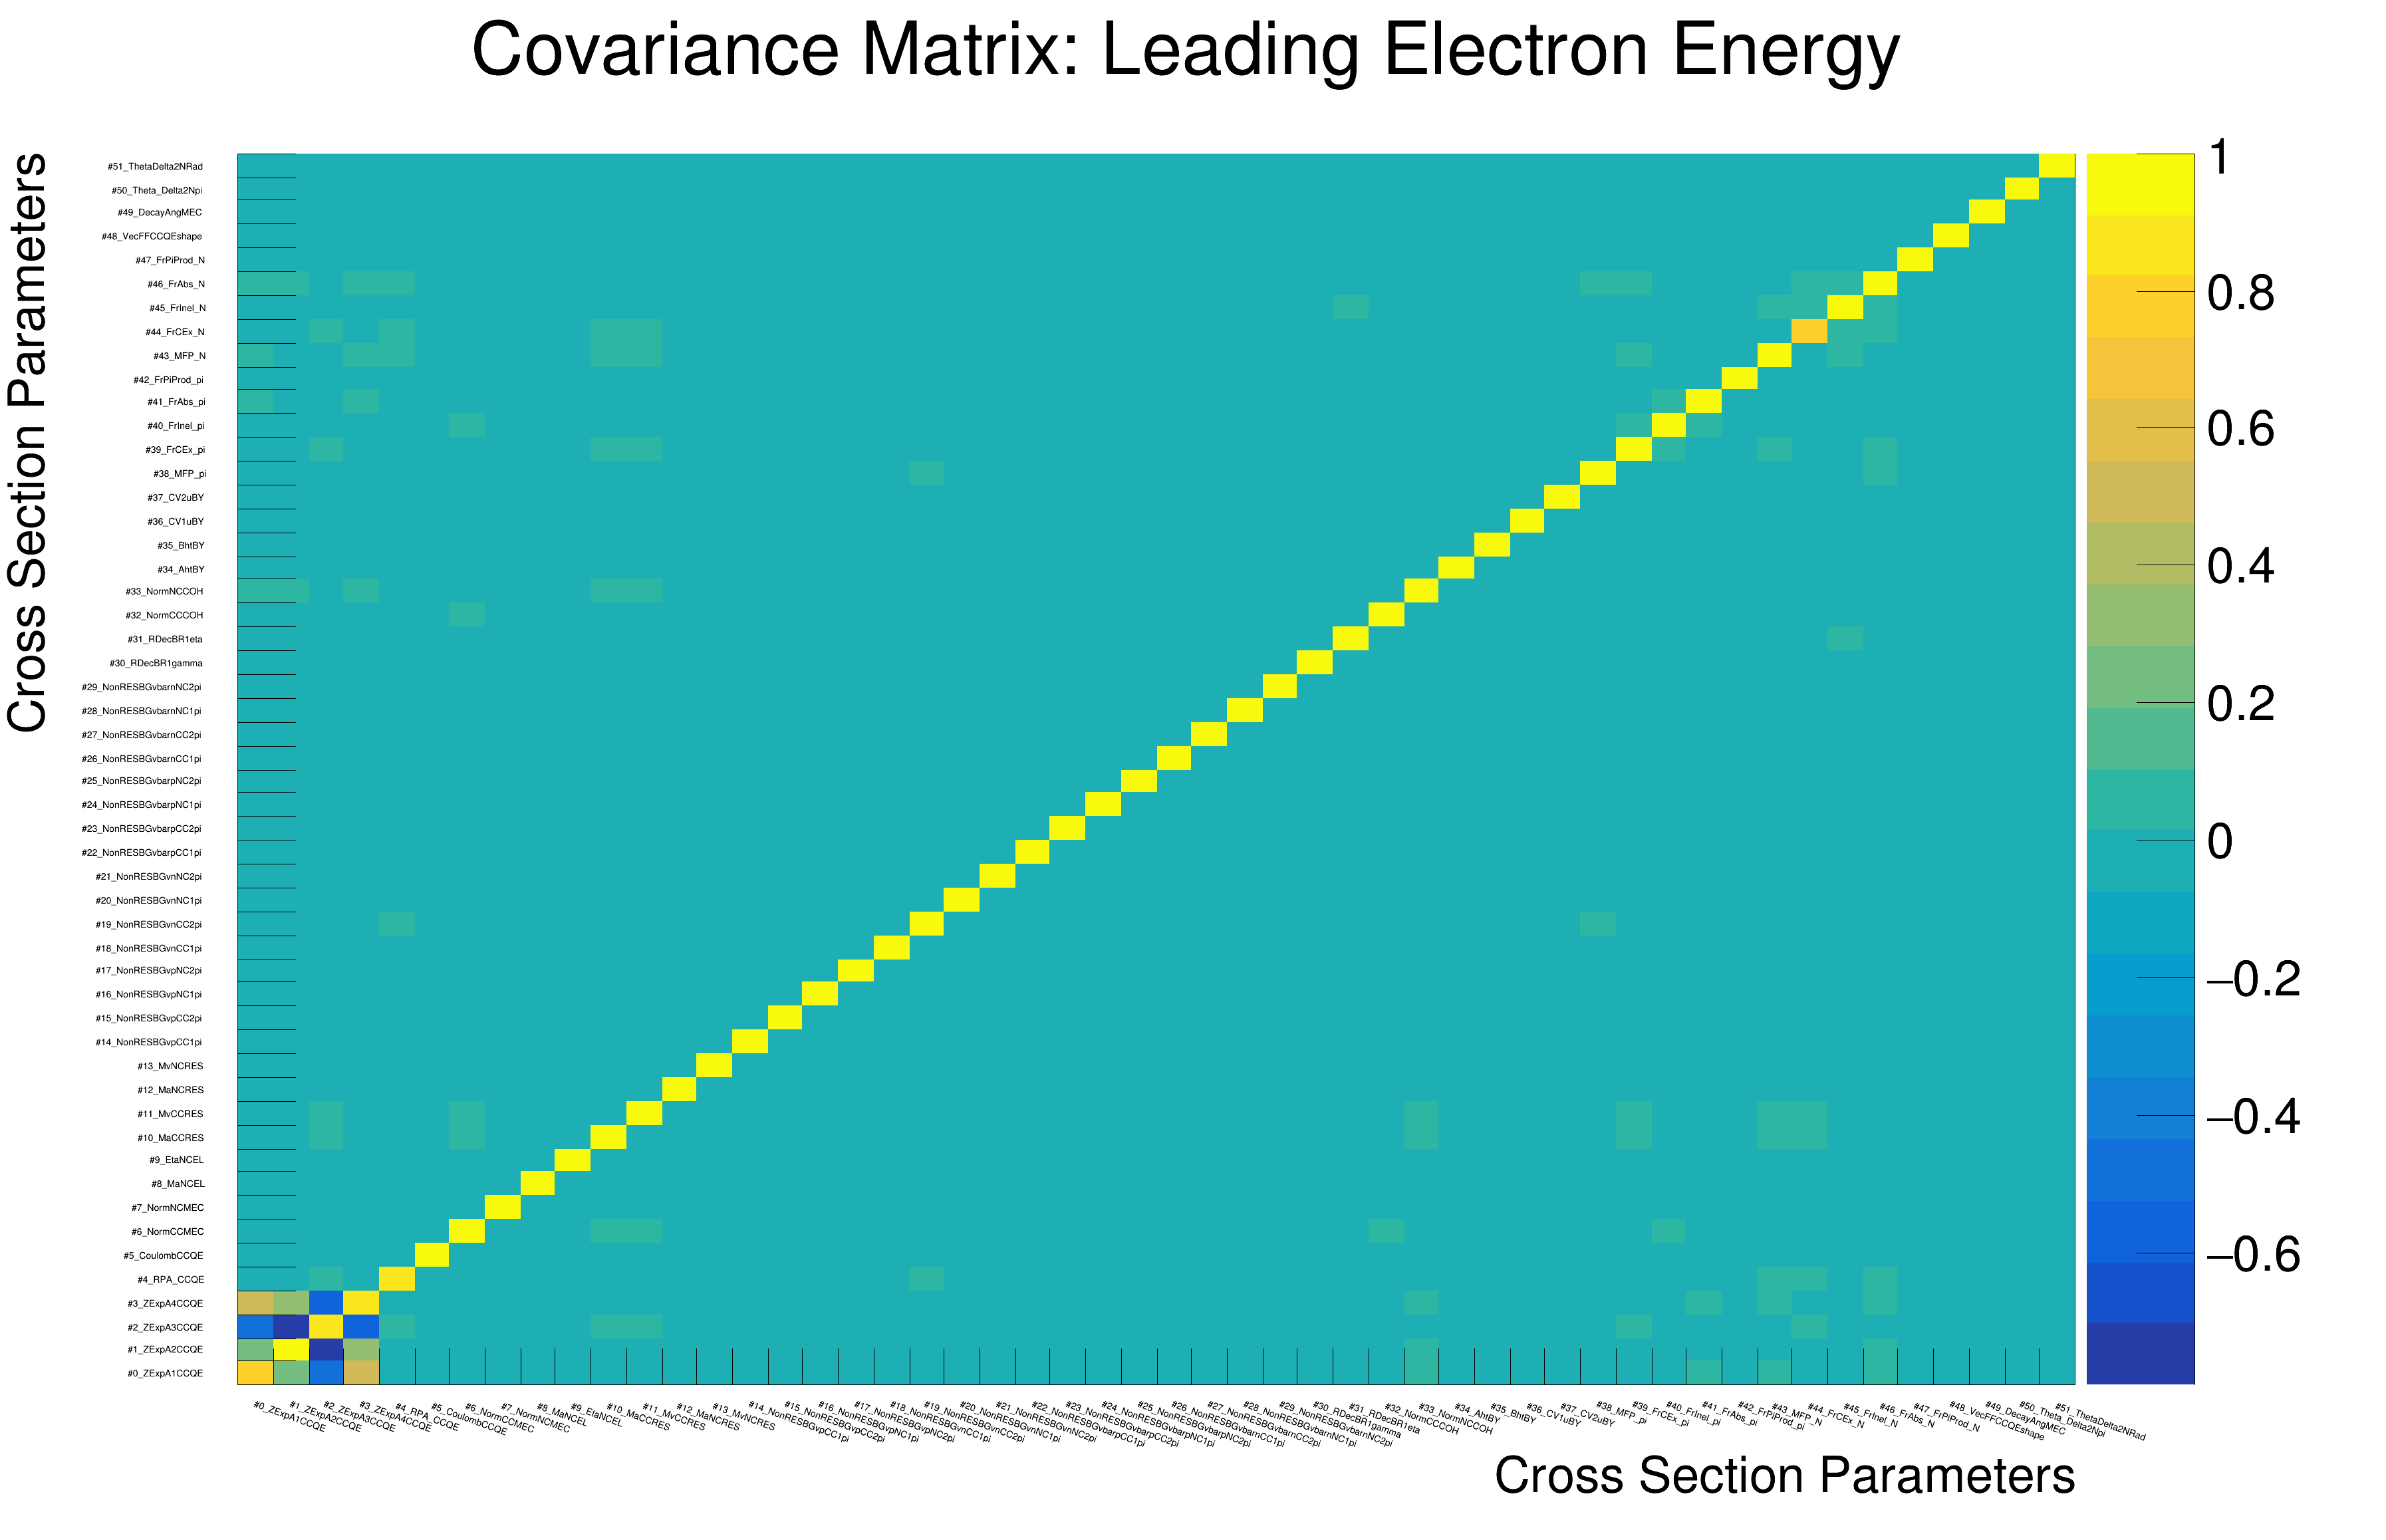

In [12]:
c1 = r.TCanvas("c1", "c1", 1200, 800)

h_cov = fFit.Get("FitterEngine/postFit/Hesse/errors/Cross section Systematics/matrices/Covariance_TH2D")
r.gStyle.SetPalette(r.kBird)

h_cov.Draw("colz")
h_cov.SetTitle("Covariance Matrix: Leading Electron Energy;Cross Section Parameters;Cross Section Parameters")
h_cov.GetXaxis().SetLabelSize(0.01)
h_cov.GetYaxis().SetLabelSize(0.01)
h_cov.GetXaxis().LabelsOption("d")
c1.SetRightMargin(0.13)
c1.Draw()

c1.SaveAs("/nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/CrossSectionCovariance.png")

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: png file /nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/CrossSectionCorrelation.png has been created


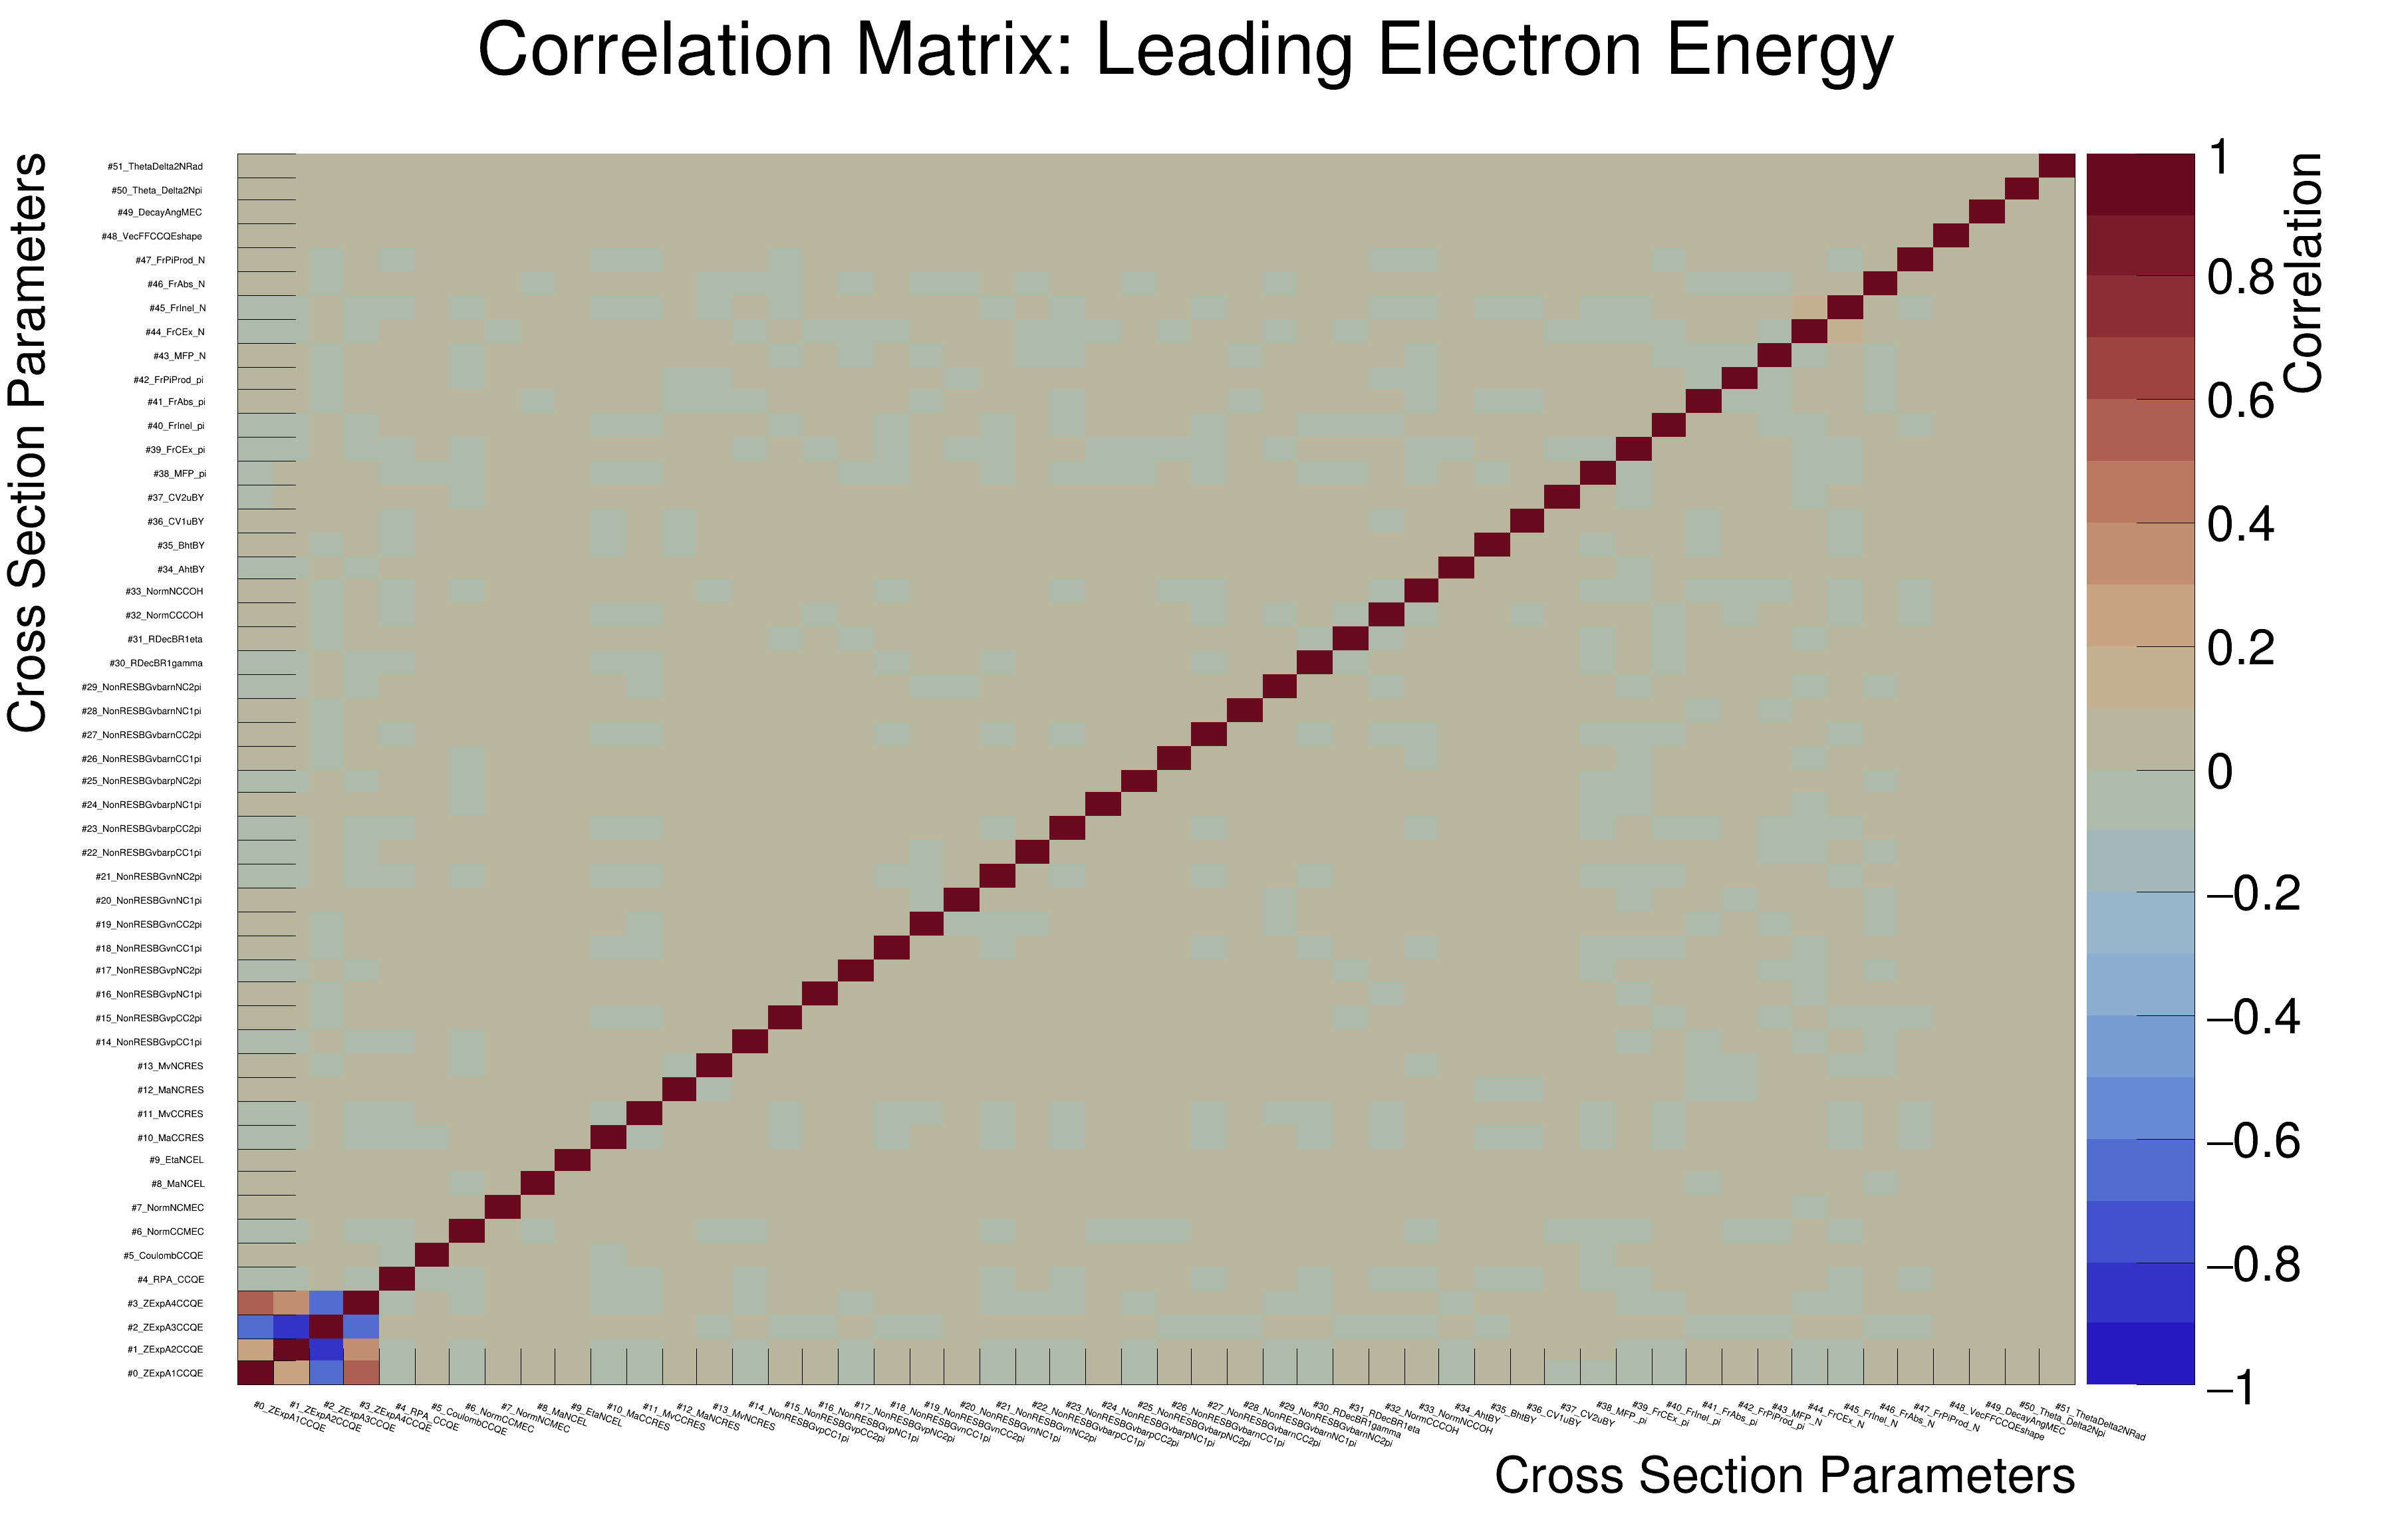

In [13]:
c1 = r.TCanvas("c1", "c1", 1200, 800)

h_cov = fFit.Get("FitterEngine/postFit/Hesse/errors/Cross section Systematics/matrices/Correlation_TH2D")
r.gStyle.SetPalette(r.kThermometer)

h_cov.Draw("colz")
h_cov.SetTitle("Correlation Matrix: Leading Electron Energy;Cross Section Parameters;Cross Section Parameters")
h_cov.GetXaxis().SetLabelSize(0.01)
h_cov.GetYaxis().SetLabelSize(0.01)
h_cov.GetXaxis().LabelsOption("d")
c1.SetRightMargin(0.13)
c1.Draw()

c1.SaveAs("/nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/CrossSectionCorrelation.png")

Info in <TCanvas::Print>: png file /nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/FluxConstraints.png has been created


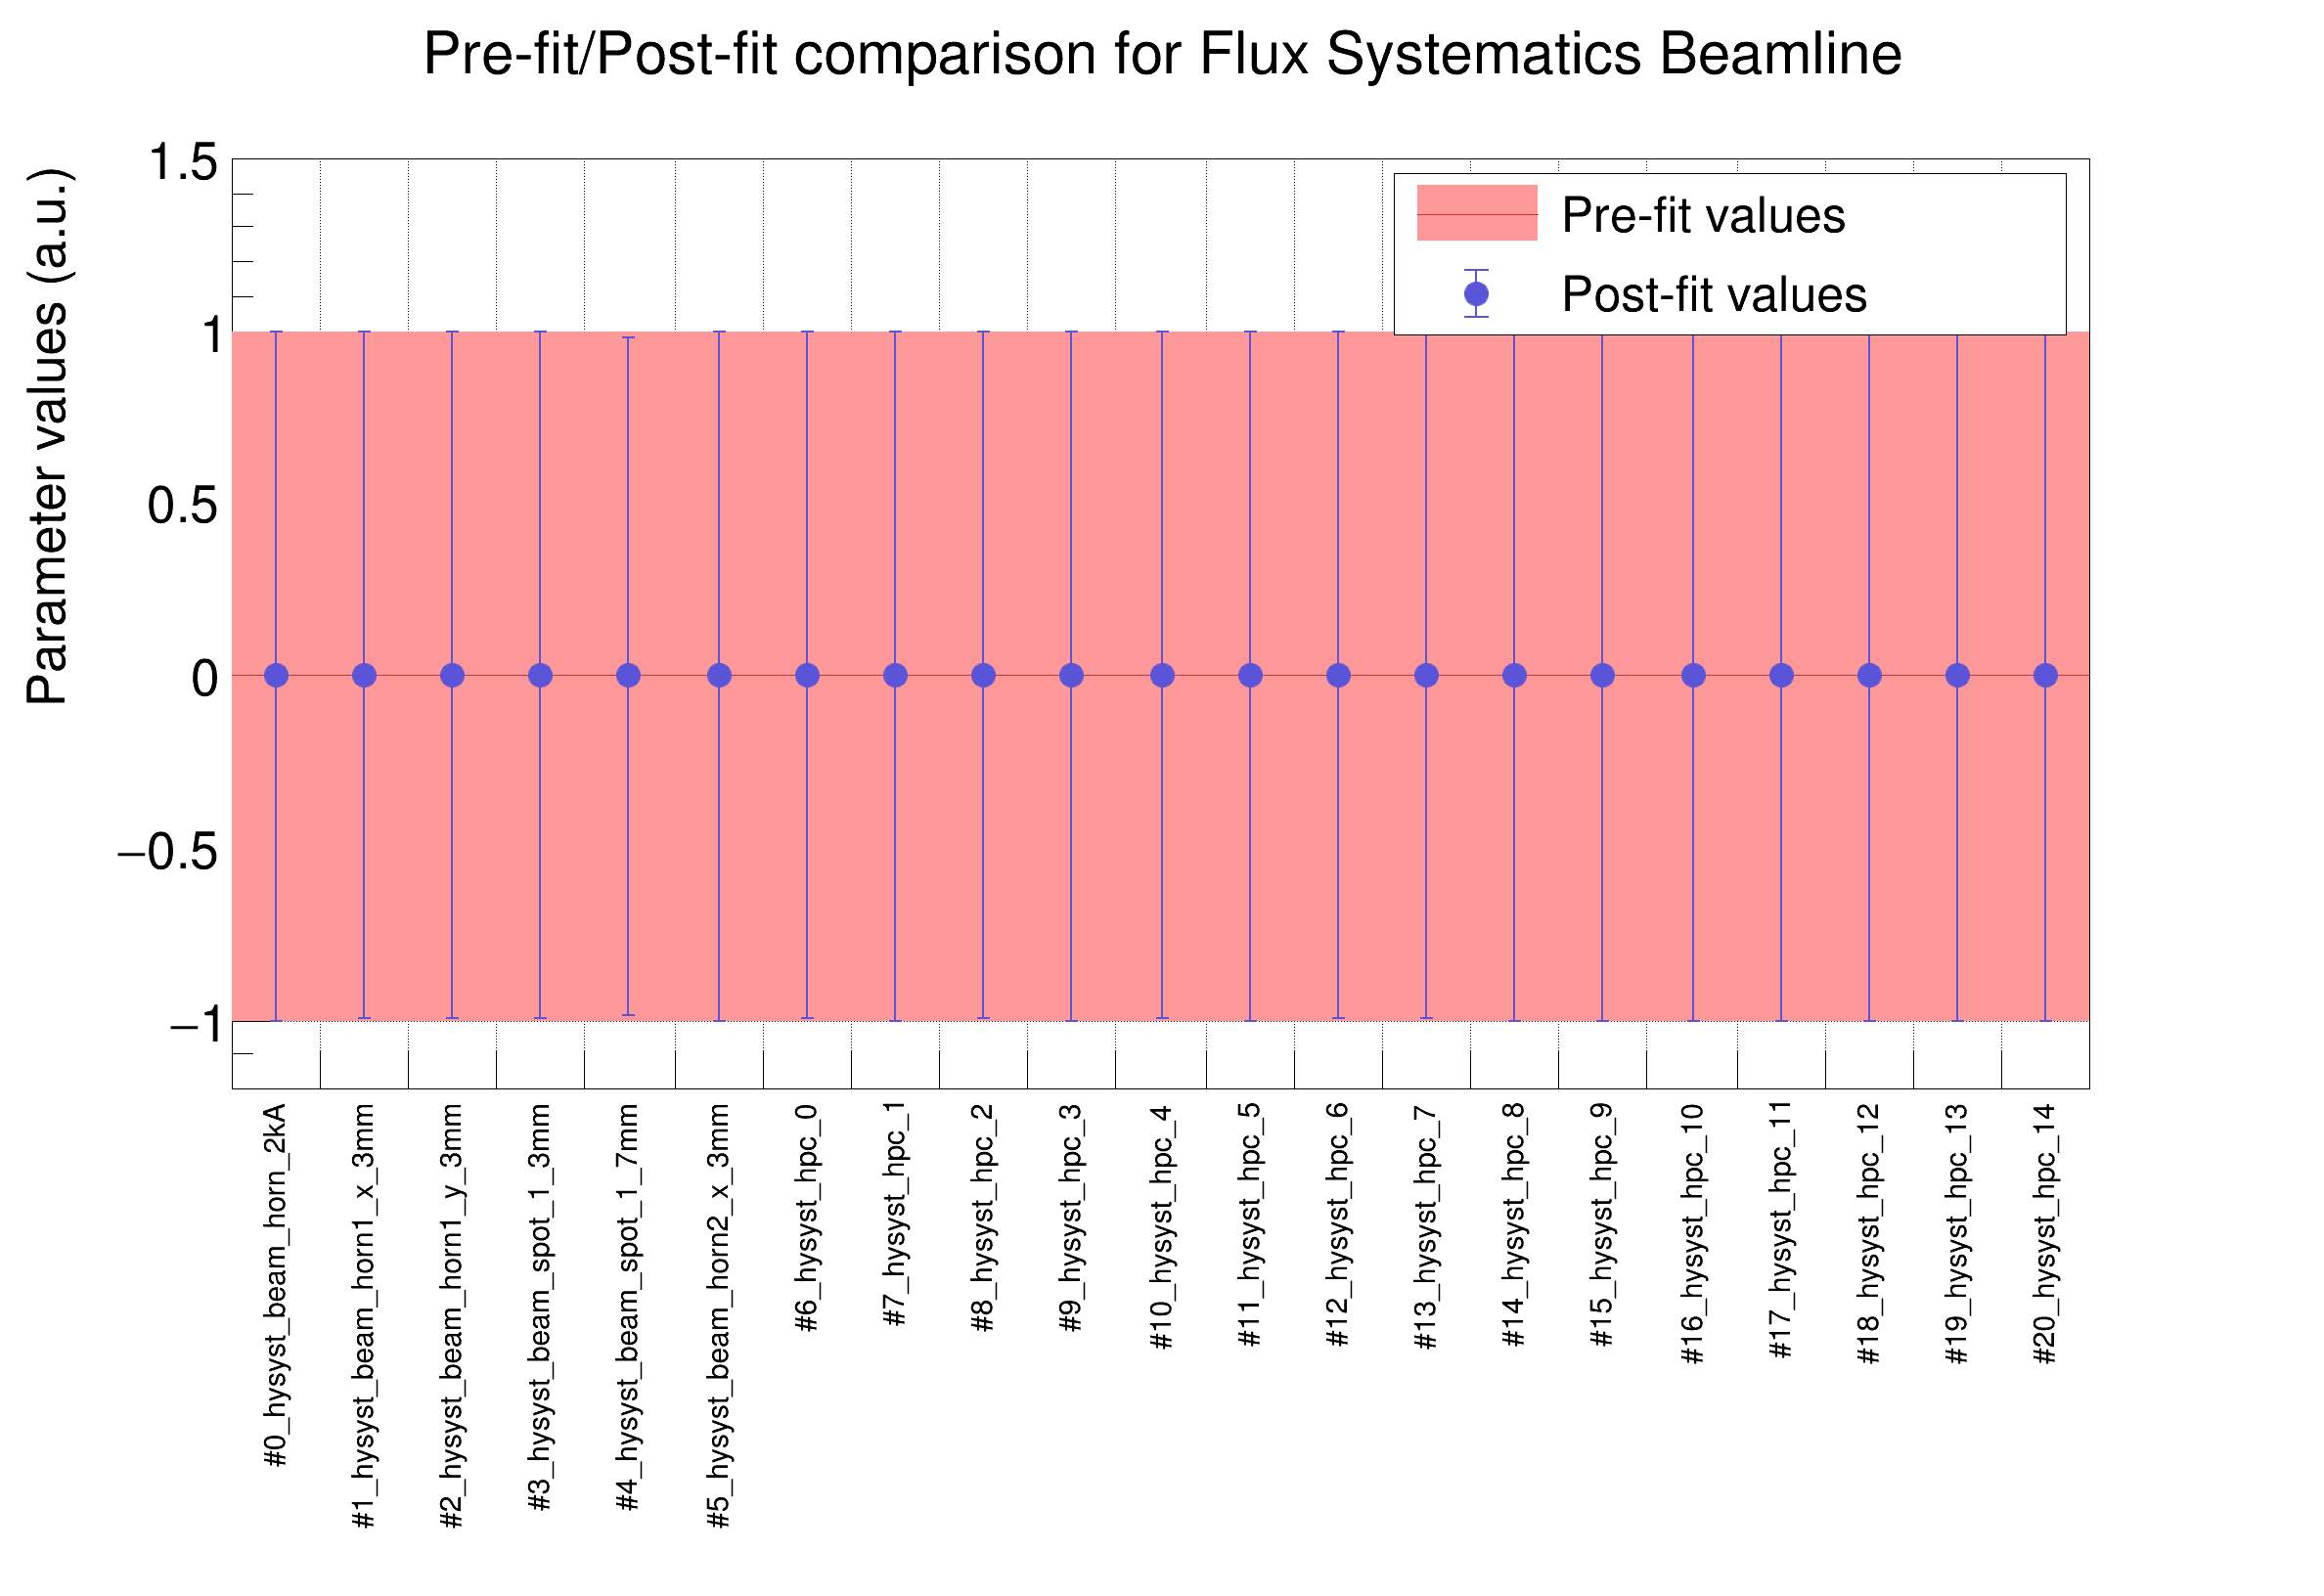

In [14]:
c_par = fFit.Get("FitterEngine/postFit/Hesse/errors/Flux Systematics Beamline/values/fitConstraints_TCanvas")

c_par.SetCanvasSize(2000, 1200)
c_par.Draw()

c_par.SaveAs("/nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/FluxConstraints.png")


Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: png file /nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/FluxCovariance.png has been created


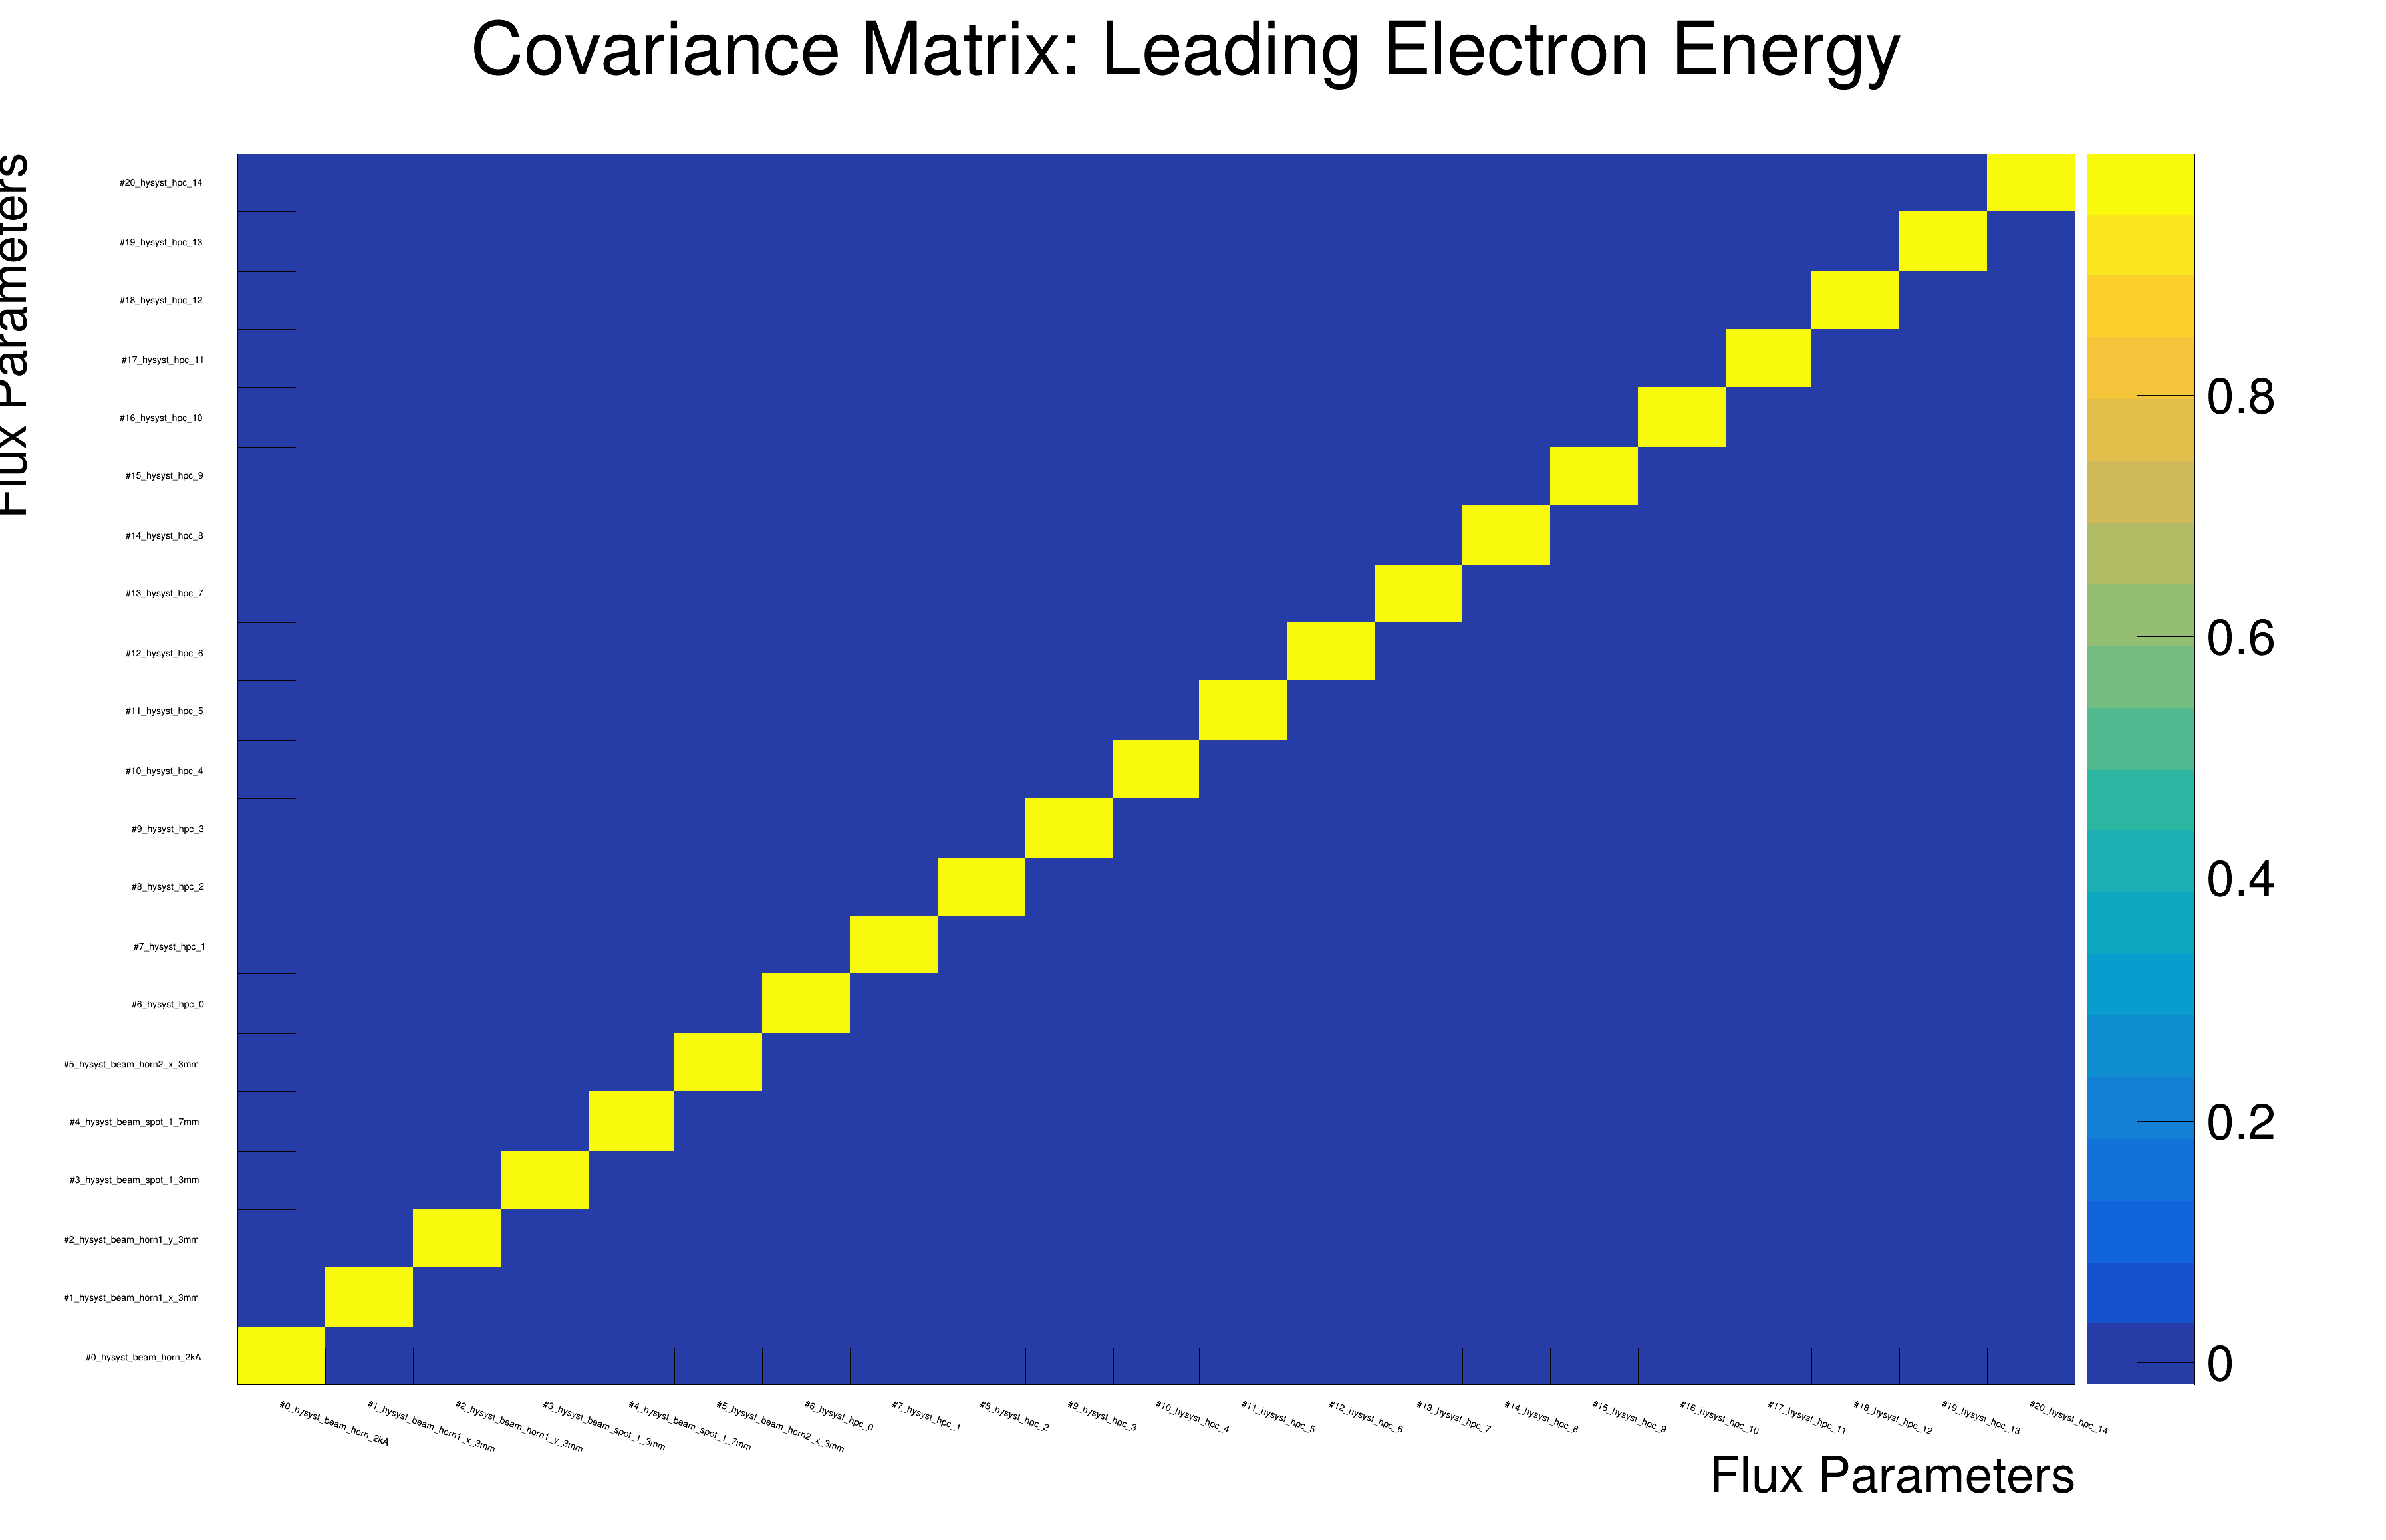

In [15]:
c1 = r.TCanvas("c1", "c1", 1200, 800)

h_cov = fFit.Get("FitterEngine/postFit/Hesse/errors/Flux Systematics Beamline/matrices/Covariance_TH2D")
r.gStyle.SetPalette(r.kBird)

h_cov.Draw("colz")
h_cov.SetTitle("Covariance Matrix: Leading Electron Energy;Flux Parameters;Flux Parameters")
h_cov.GetXaxis().SetLabelSize(0.01)
h_cov.GetYaxis().SetLabelSize(0.01)
h_cov.GetXaxis().LabelsOption("d")
c1.SetRightMargin(0.13)
c1.Draw()

c1.SaveAs("/nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/FluxCovariance.png")

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: png file /nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/FluxCorrelation.png has been created


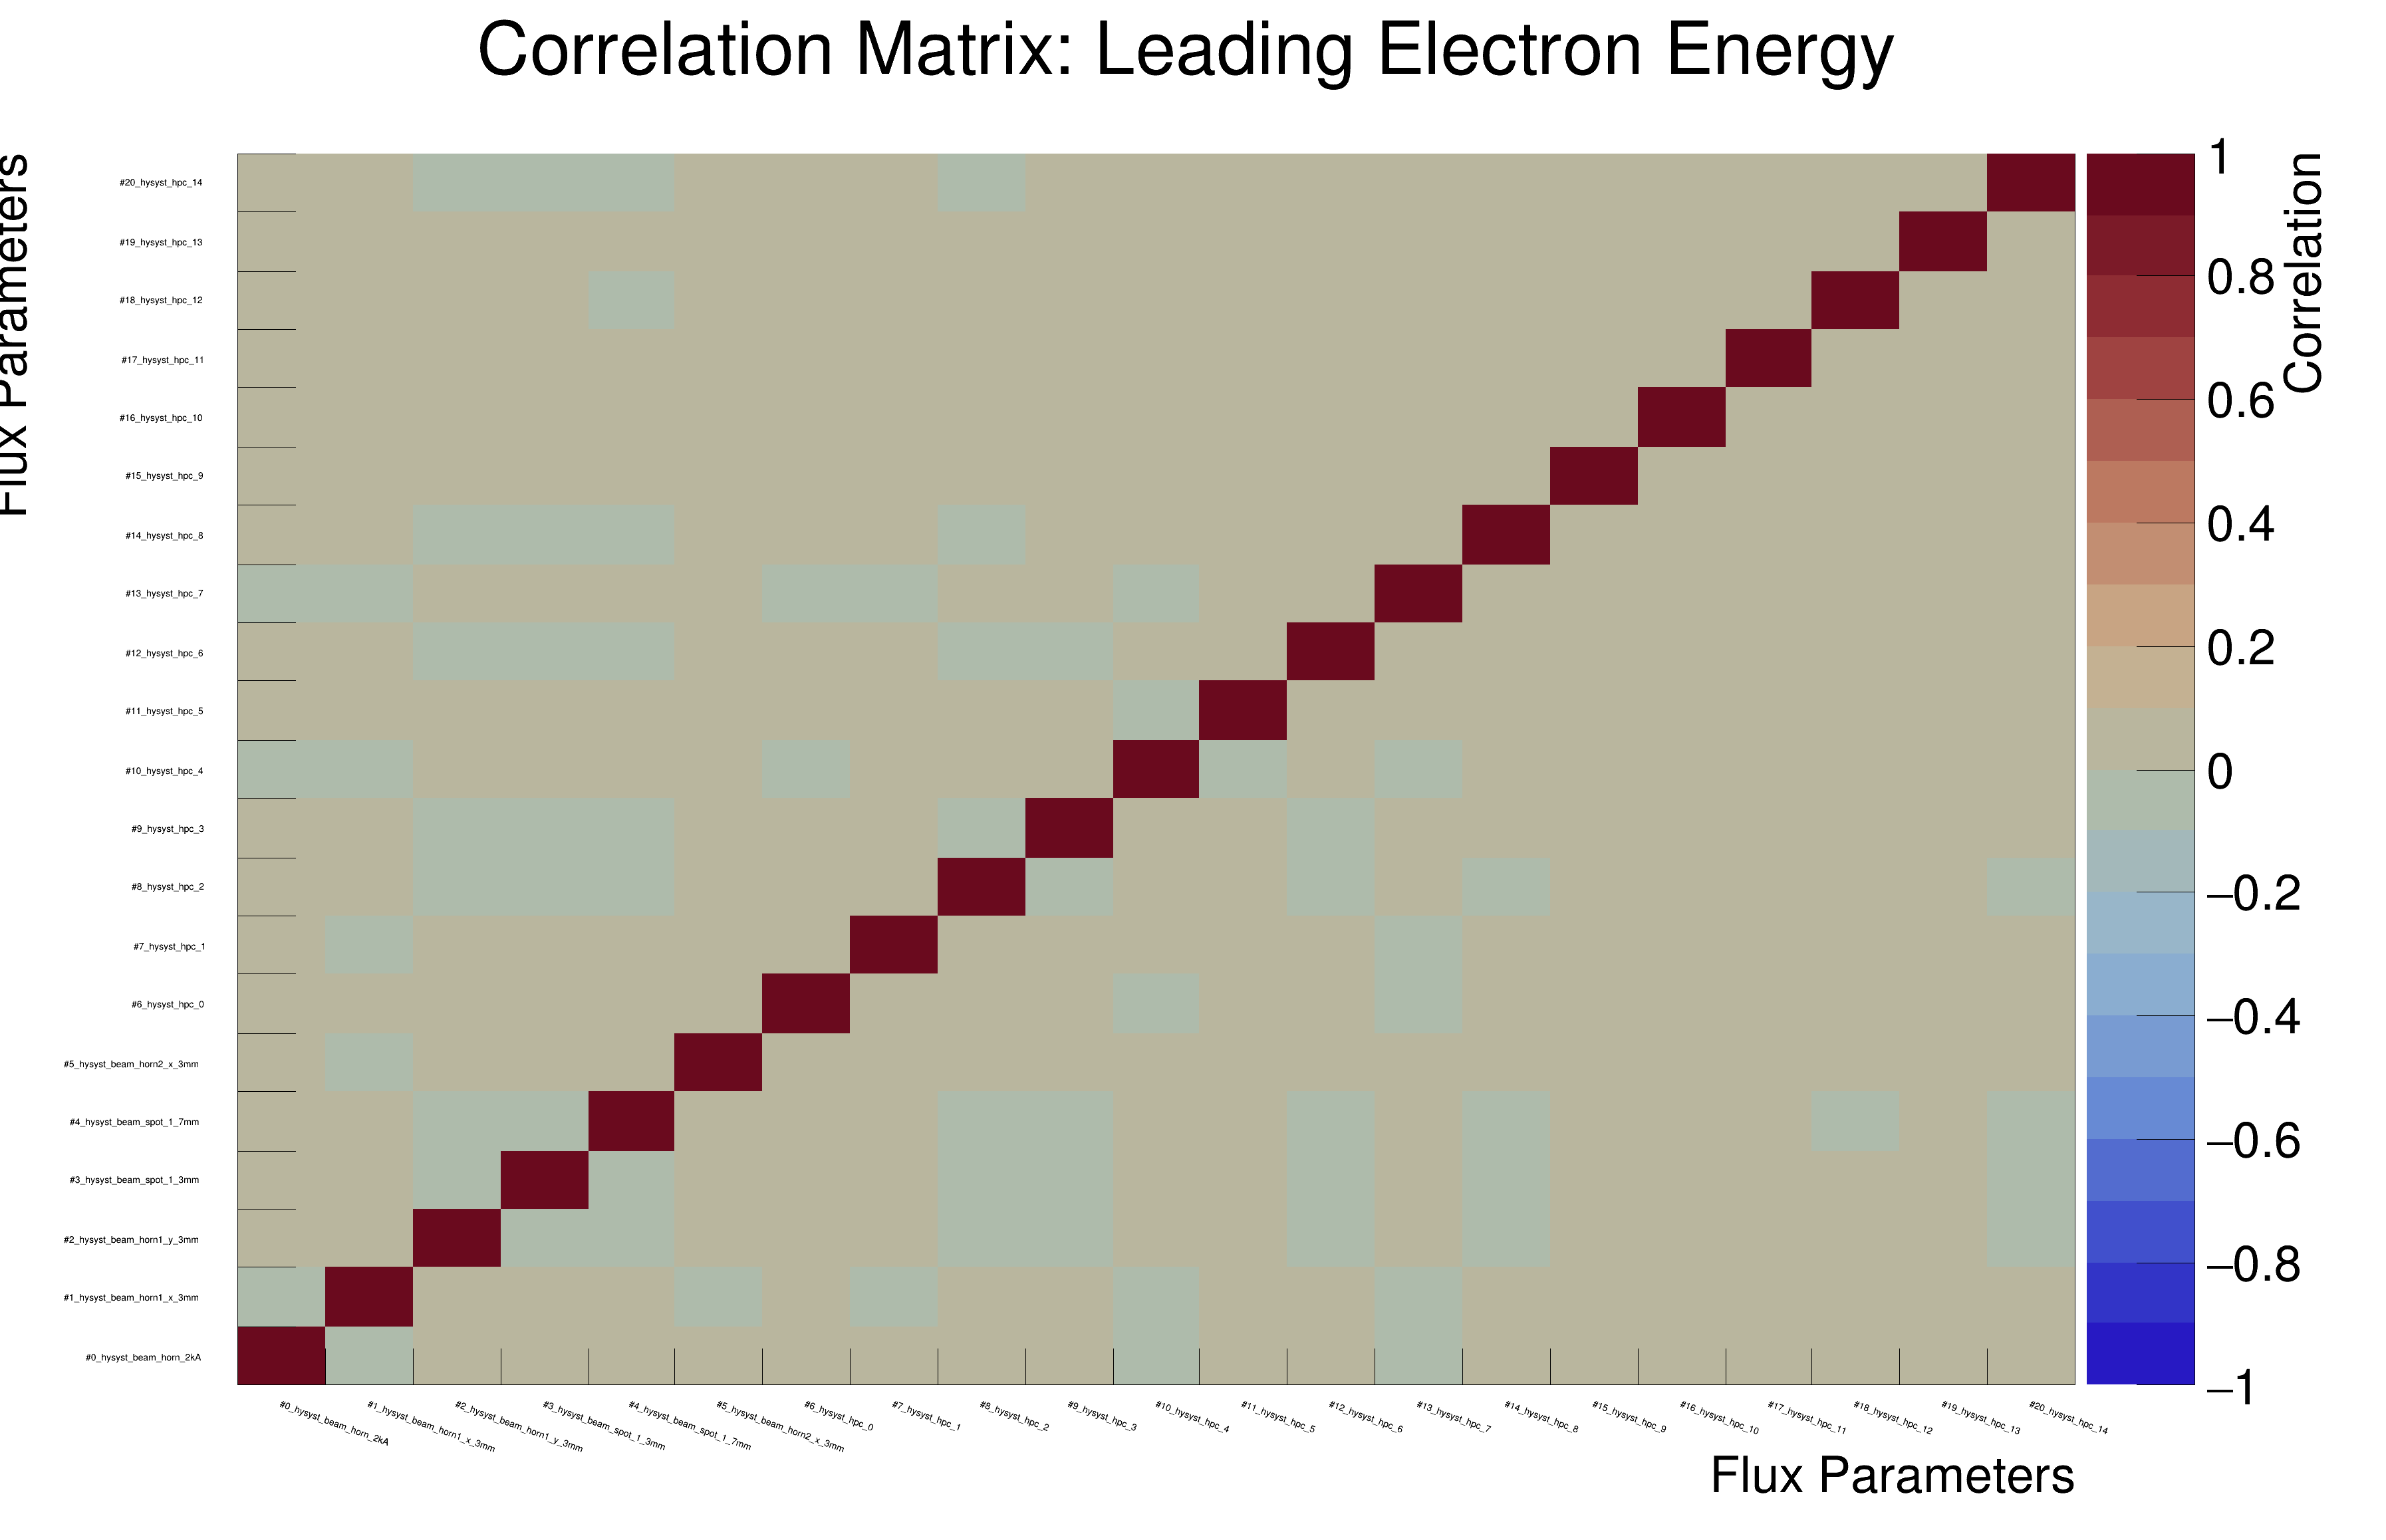

In [16]:
c1 = r.TCanvas("c1", "c1", 1200, 800)

h_cov = fFit.Get("FitterEngine/postFit/Hesse/errors/Flux Systematics Beamline/matrices/Correlation_TH2D")
r.gStyle.SetPalette(r.kThermometer)

h_cov.Draw("colz")
h_cov.SetTitle("Correlation Matrix: Leading Electron Energy;Flux Parameters;Flux Parameters")
h_cov.GetXaxis().SetLabelSize(0.01)
h_cov.GetYaxis().SetLabelSize(0.01)
h_cov.GetXaxis().LabelsOption("d")
c1.SetRightMargin(0.13)
c1.Draw()

c1.SaveAs("/nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/FluxCorrelation.png")

Info in <TCanvas::Print>: png file /nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/DetectorConstraints.png has been created


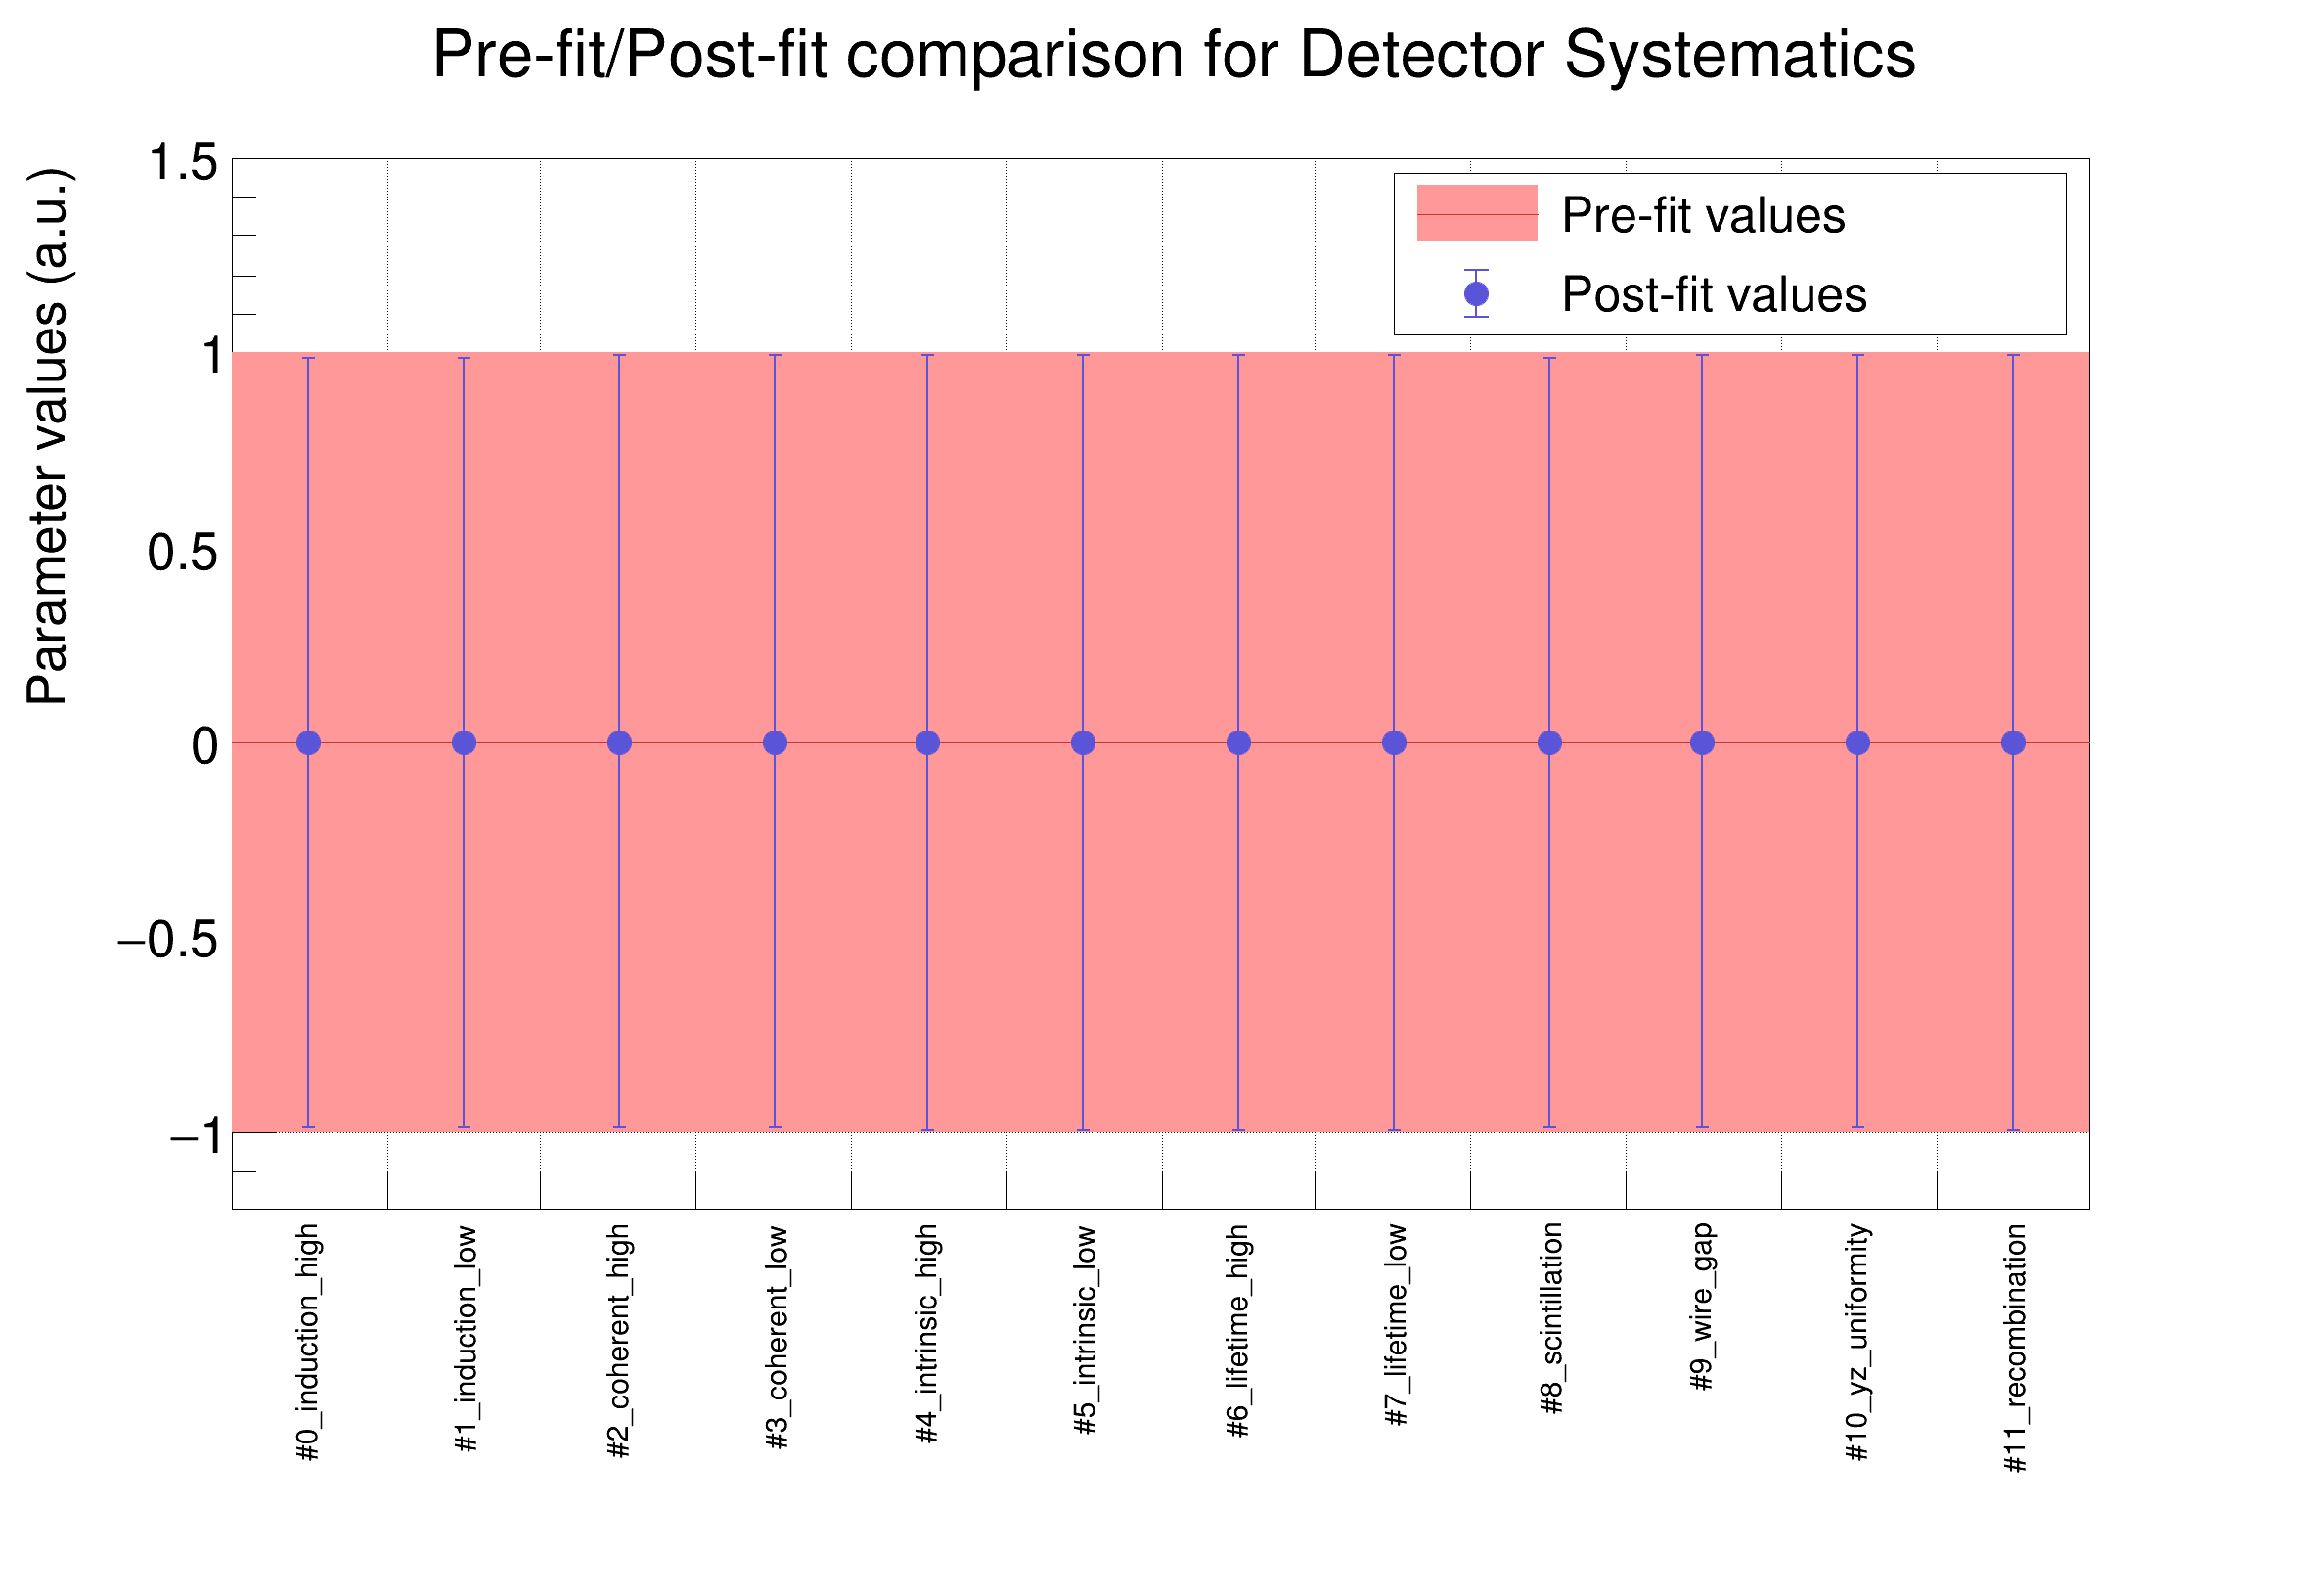

In [17]:
c_par = fFit.Get("FitterEngine/postFit/Hesse/errors/Detector Systematics/values/fitConstraints_TCanvas")

c_par.SetCanvasSize(2000, 1200)
c_par.Draw()

c_par.SaveAs("/nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/DetectorConstraints.png")

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: png file /nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/DetectorCovariance.png has been created


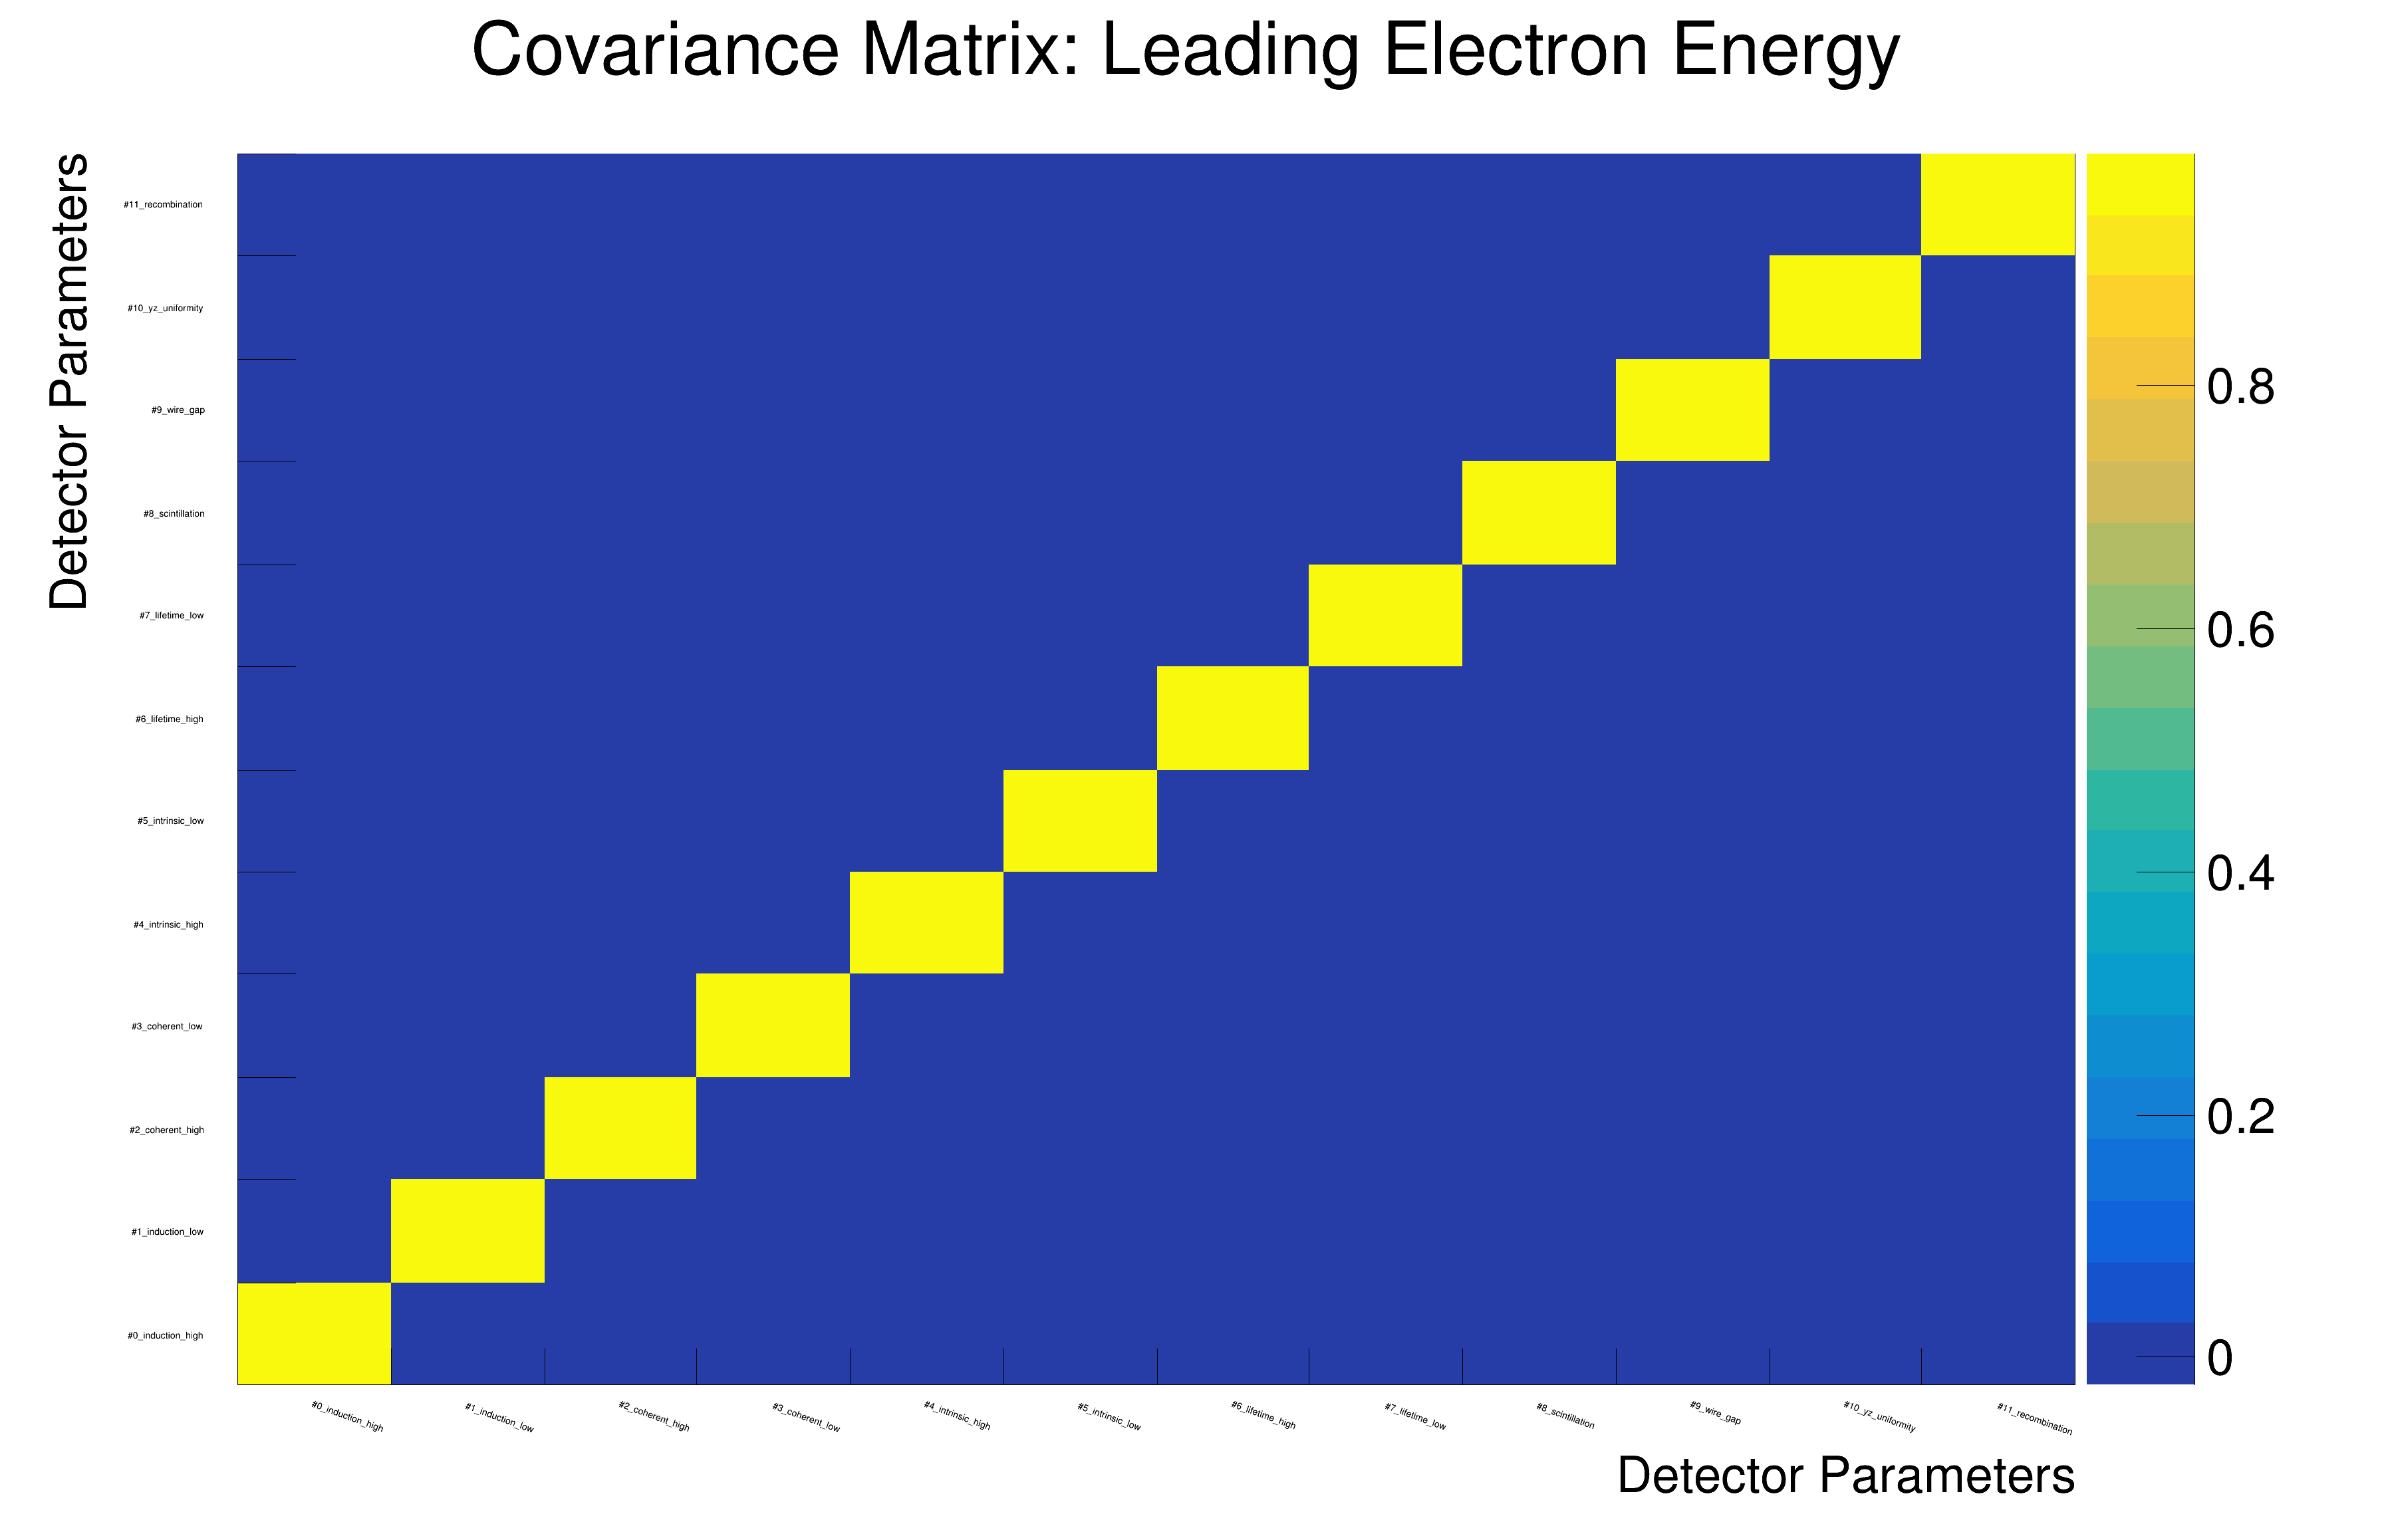

In [18]:
c1 = r.TCanvas("c1", "c1", 1200, 800)

h_cov = fFit.Get("FitterEngine/postFit/Hesse/errors/Detector Systematics/matrices/Covariance_TH2D")
r.gStyle.SetPalette(r.kBird)

h_cov.Draw("colz")
h_cov.SetTitle("Covariance Matrix: Leading Electron Energy;Detector Parameters;Detector Parameters")
h_cov.GetXaxis().SetLabelSize(0.01)
h_cov.GetYaxis().SetLabelSize(0.01)
h_cov.GetXaxis().LabelsOption("d")
c1.SetRightMargin(0.13)
c1.Draw()

c1.SaveAs("/nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/DetectorCovariance.png")

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: png file /nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/DetectorCorrelation.png has been created


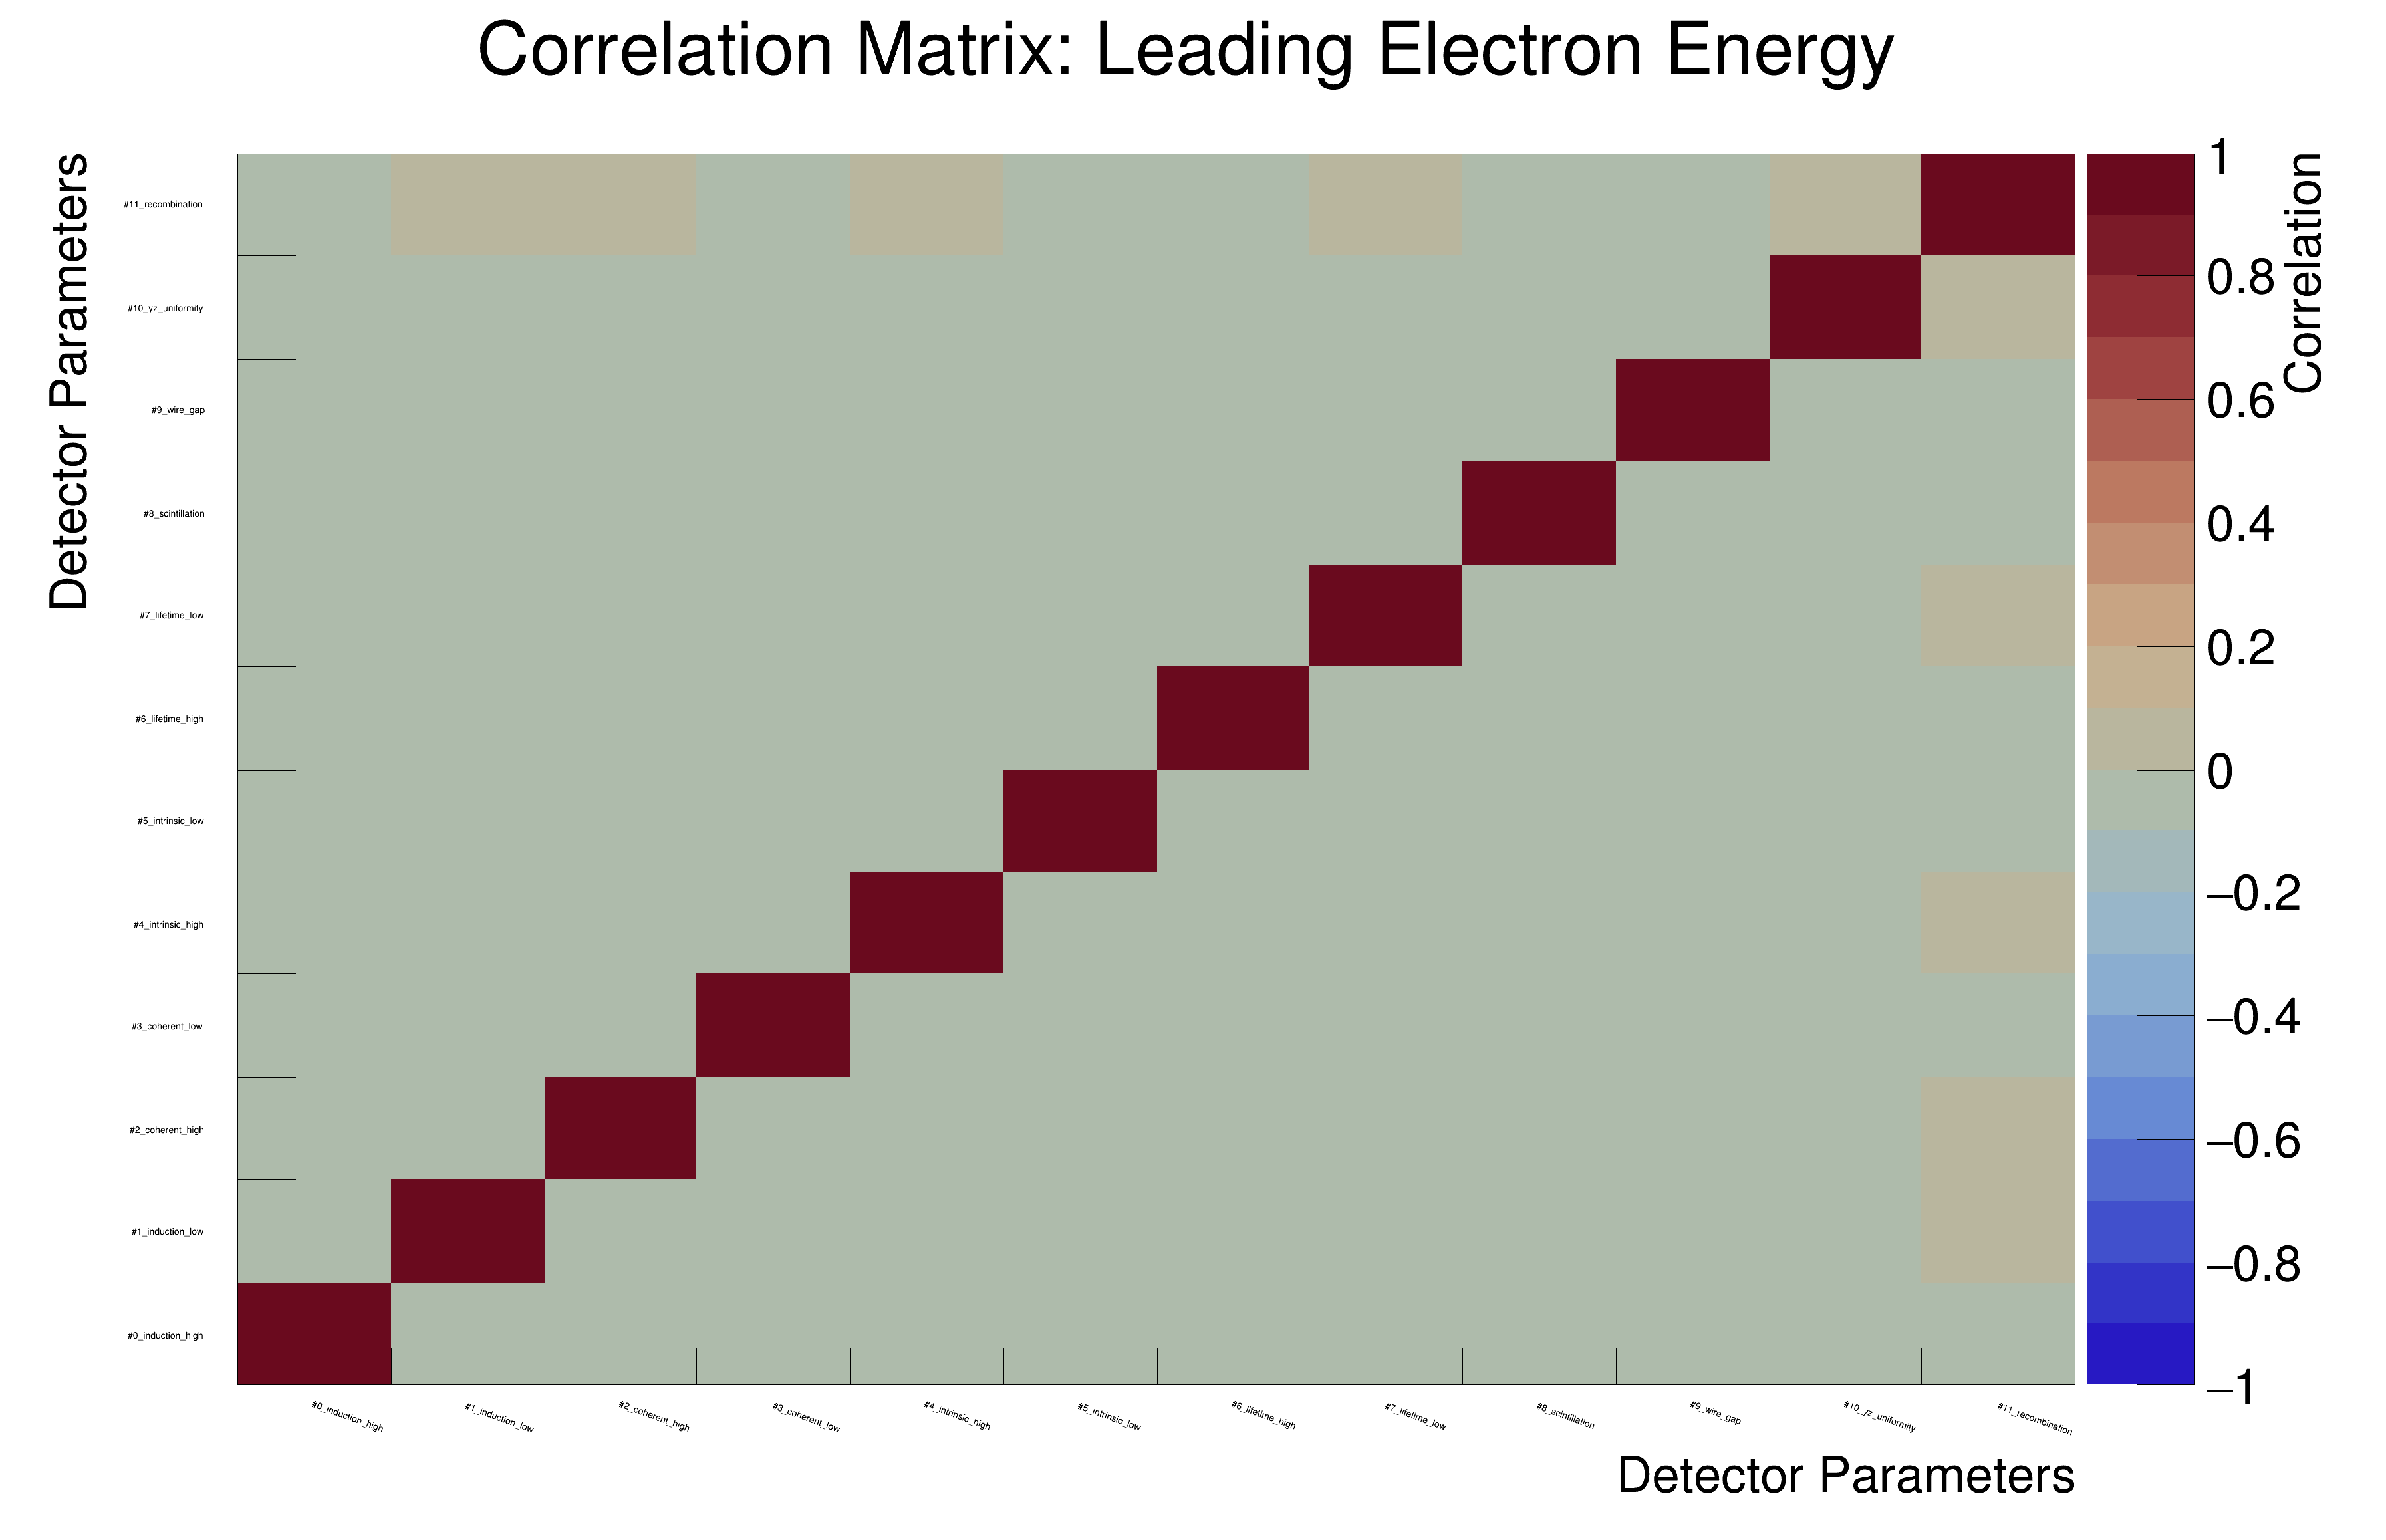

In [19]:
c1 = r.TCanvas("c1", "c1", 1200, 800)

h_cov = fFit.Get("FitterEngine/postFit/Hesse/errors/Detector Systematics/matrices/Correlation_TH2D")
r.gStyle.SetPalette(r.kThermometer)

h_cov.Draw("colz")
h_cov.SetTitle("Correlation Matrix: Leading Electron Energy;Detector Parameters;Detector Parameters")
h_cov.GetXaxis().SetLabelSize(0.01)
h_cov.GetYaxis().SetLabelSize(0.01)
h_cov.GetXaxis().LabelsOption("d")
c1.SetRightMargin(0.13)
c1.Draw()

c1.SaveAs("/nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/DetectorCorrelation.png")

## Draw pre/post fit error bars

## Plot asimov dataset pre and post fit

In [20]:
h_errors_pre = fPreError.Get("toyGen/histograms/signal_EleE_pre_fit_TH1D")  # errors
h_errors_post = fPostError.Get("toyGen/histograms/signal_EleE_TH1D")  # errors

h_data = fPostError.Get("toyGen/plots/histograms/signal_EleE/reco_leading_electron_energy/Data_TH1D")  # data

postFitErrors = []
preFitErrors = []
x_vals = []
widths = []
for i in range(1, h_errors_pre.GetNbinsX() + 1):
    bounds = [float(x) for x in h_errors_pre.GetXaxis().GetBinLabel(i).split(':')[-1].strip().replace("[", "").replace("]", "").split(',')]
    width = bounds[1] - bounds[0]
    widths.append(width)
    preFitErrors.append(h_errors_pre.GetBinError(i) * width)
    postFitErrors.append(h_errors_post.GetBinError(i) * width)
    x_vals.append((bounds[0] + bounds[1]) / 2)
    print("bin bounds:", bounds, "bin width:", width)

def get_mc_hist(file_obj, category_index, mode):
    """Get category histogram from ROOT file with path fallbacks across file variants."""
    candidates = []
    if mode == "pre":
        candidates = [
            f"toyGen/plots/histograms/signal_EleE (pre-fit)/reco_leading_electron_energy/category/{category_index}/MC_TH1D",
            f"toyGen/plots/histograms/signal_EleE/reco_leading_electron_energy/category/{category_index}/MC_TH1D",
            f"toyGen/plots/histograms/signal_EleE_pre_fit/reco_leading_electron_energy/category/{category_index}/MC_TH1D",
        ]
    else:
        candidates = [
            f"toyGen/plots/histograms/signal_EleE (post-fit)/reco_leading_electron_energy/category/{category_index}/MC_TH1D",
            f"toyGen/plots/histograms/signal_EleE/reco_leading_electron_energy/category/{category_index}/MC_TH1D",
            f"toyGen/plots/histograms/signal_EleE_post_fit/reco_leading_electron_energy/category/{category_index}/MC_TH1D",
        ]

    for path in candidates:
        obj = file_obj.Get(path)
        if obj and hasattr(obj, "GetBinContent"):
            return obj
    raise RuntimeError(f"Could not find MC_TH1D for category {category_index} in {mode}-fit file")

h_mc_pre = []
h_mc_post = []
for i in range(0, 5):
    pre_bin_content = []
    post_bin_content = []
    h_data_pre = get_mc_hist(fPreError, i, "pre")
    h_data_post = get_mc_hist(fPostError, i, "post")
    for j in range(h_data_pre.GetNbinsX()):
        pre_bin_content.append(h_data_pre.GetBinContent(j + 1))
        post_bin_content.append(h_data_post.GetBinContent(j + 1))
    h_mc_pre.append(pre_bin_content)
    h_mc_post.append(post_bin_content)

data = []
data_err = []
for i in range(1, h_data.GetNbinsX() + 1):
    data.append(h_data.GetBinContent(i))
    data_err.append(h_data.GetBinError(i))

bin bounds: [300.0, 390.0] bin width: 90.0
bin bounds: [390.0, 490.0] bin width: 100.0
bin bounds: [490.0, 600.0] bin width: 110.0
bin bounds: [600.0, 730.0] bin width: 130.0
bin bounds: [730.0, 870.0] bin width: 140.0
bin bounds: [870.0, 1030.0] bin width: 160.0
bin bounds: [1030.0, 1240.0] bin width: 210.0
bin bounds: [1240.0, 1500.0] bin width: 260.0
bin bounds: [1500.0, 2000.0] bin width: 500.0
bin bounds: [2000.0, 5000.0] bin width: 3000.0


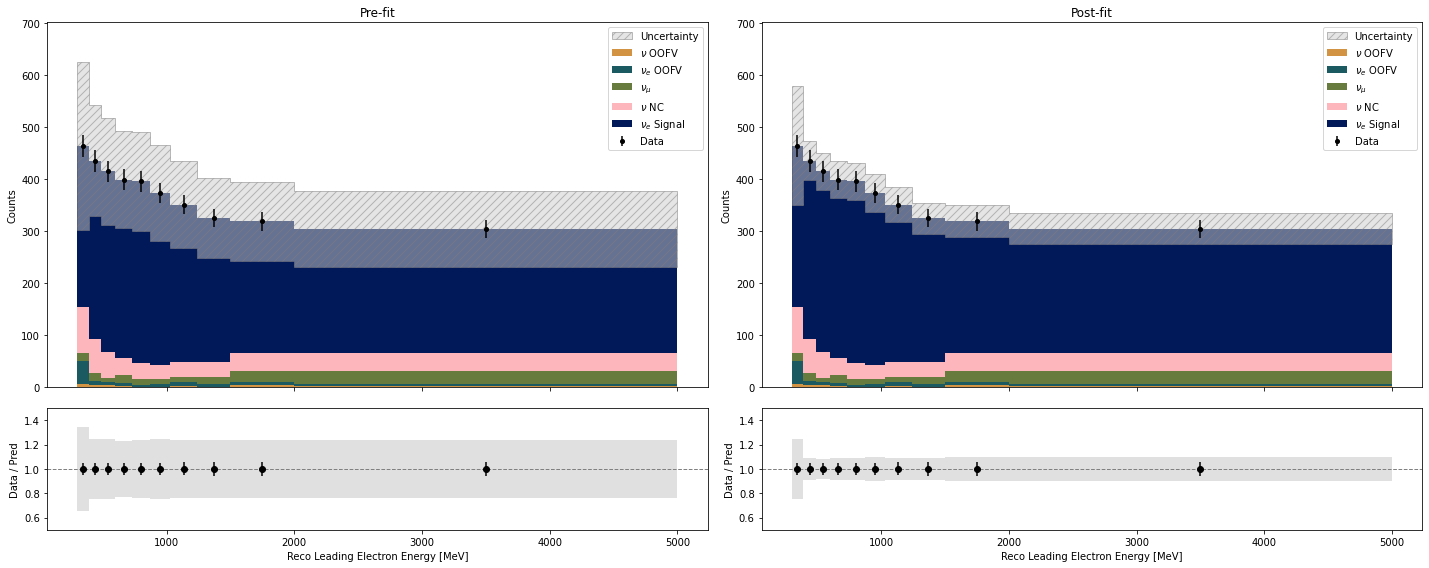

In [21]:
data_pre = np.array(h_mc_pre)
data_post = np.array(h_mc_post)

n_bins = len(x_vals)

labels = [r"$\nu_e$ Signal", r"$\nu_e$ OOFV", r"$\nu_\mu$", r"$\nu$ OOFV", r"$\nu$ NC"]
category_colors = ['#011959', '#1C5A62', '#687B3E', '#D29343', '#FDB7BC']

def draw_stacked_with_band(ax, stack_data, errors, title, data_y=None, data_yerr=None):
    bottom = np.zeros(n_bins)
    totals_per_cat = stack_data.sum(axis=1)
    order = np.argsort(totals_per_cat)  # draw from smallest to largest contribution

    for i in order:
        ax.bar(
            x_vals,
            stack_data[i],
            bottom=bottom,
            width=widths,
            label=labels[i],
            color=category_colors[i],
            align='center'
        )
        bottom += stack_data[i]

    # total prediction and band
    x_edges = [x_vals[0] - widths[0] / 2.0]
    x_edges.extend([x + w / 2.0 for x, w in zip(x_vals, widths)])
    total_pred = np.sum(stack_data, axis=0)
    err = np.asarray(errors, dtype=float)
    lower = np.maximum(0.0, total_pred - err)
    upper = total_pred + err
    ax.fill_between(
        x_edges,
        np.r_[lower, lower[-1]],
        np.r_[upper, upper[-1]],
        step='post',
        facecolor='0.8',
        edgecolor='gray',
        hatch='///',
        alpha=0.5,
        label='Uncertainty'
    )

    # data points
    if data_y is not None:
        y = np.asarray(data_y, dtype=float)
        yerr = np.asarray(data_yerr, dtype=float) if data_yerr is not None else np.zeros_like(y)
        ax.errorbar(
            x_vals,
            y,
            yerr=yerr,
            fmt='o',
            color='black',
            ecolor='black',
            elinewidth=1.5,
            capsize=0,
            markersize=4,
            label='Data',
            zorder=10
        )

    ax.set_ylabel("Counts")
    ax.set_title(title)
    return x_edges, total_pred, err

def draw_ratio(ax, total_pred, err, data_y, data_yerr, x_edges, center=1.0, ypad=(0.5, 1.5)):
    tot = np.asarray(total_pred, dtype=float)
    data_y = np.asarray(data_y, dtype=float)
    data_yerr = np.asarray(data_yerr, dtype=float)

    denom = tot.copy()
    denom[denom == 0.0] = np.nan
    ratio = data_y / denom
    ratio_err = data_yerr / denom

    lower = np.maximum(0.0, (tot - err) / denom)
    upper = (tot + err) / denom

    ax.fill_between(
        x_edges,
        np.r_[lower, lower[-1]],
        np.r_[upper, upper[-1]],
        step='post',
        facecolor='0.8',
        edgecolor='none',
        alpha=0.6,
        zorder=1,
    )
    ax.errorbar(x_vals, ratio, yerr=ratio_err, fmt='o', color='black', zorder=10)
    ax.axhline(center, color='gray', linestyle='--', linewidth=1)
    ax.set_ylim(ypad)
    ax.set_xlabel("Reco Leading Electron Energy [MeV]")
    ax.set_ylabel("Data / Pred")

# Draw main + ratio panels
fig, axes = plt.subplots(2, 2, figsize=(20, 8), gridspec_kw={'height_ratios': [3, 1]}, sharex='col')
ax1_main, ax2_main = axes[0, 0], axes[0, 1]
ax1_ratio, ax2_ratio = axes[1, 0], axes[1, 1]

edges1, tot1, err1 = draw_stacked_with_band(ax1_main, data_pre, preFitErrors, "Pre-fit", data, data_err)
edges2, tot2, err2 = draw_stacked_with_band(ax2_main, data_post, postFitErrors, "Post-fit", data, data_err)

draw_ratio(ax1_ratio, tot1, err1, data, data_err, edges1)
draw_ratio(ax2_ratio, tot2, err2, data, data_err, edges2)

ax1_main.legend(loc='upper right')
# Compute a shared y-limit for the two main panels and apply it to both
# Use the total prediction plus the MC error envelope to determine the max
ymax1 = np.nanmax(tot1 + err1) if len(tot1) and len(err1) else 0.0
ymax2 = np.nanmax(tot2 + err2) if len(tot2) and len(err2) else 0.0
shared_ymax = max(ymax1, ymax2)
# add a small padding fraction and ensure a sensible minimum
pad = 0.12
shared_ymax = max(1.0, shared_ymax * (1.0 + pad))
ax1_main.set_ylim(0.0, shared_ymax)
ax2_main.set_ylim(0.0, shared_ymax)
ax1_main.legend(loc='upper right')
ax2_main.legend(loc='upper right')
plt.tight_layout()
plt.show()


In [5]:
fin = r.TFile.Open("/exp/icarus/app/users/micarrig/BuildEventGenerators/weighted_flux.root")
h = fin.Get('h_Enu_nue_weighted')

Warning in <TCanvas::Constructor>: Deleting canvas with same name: C1


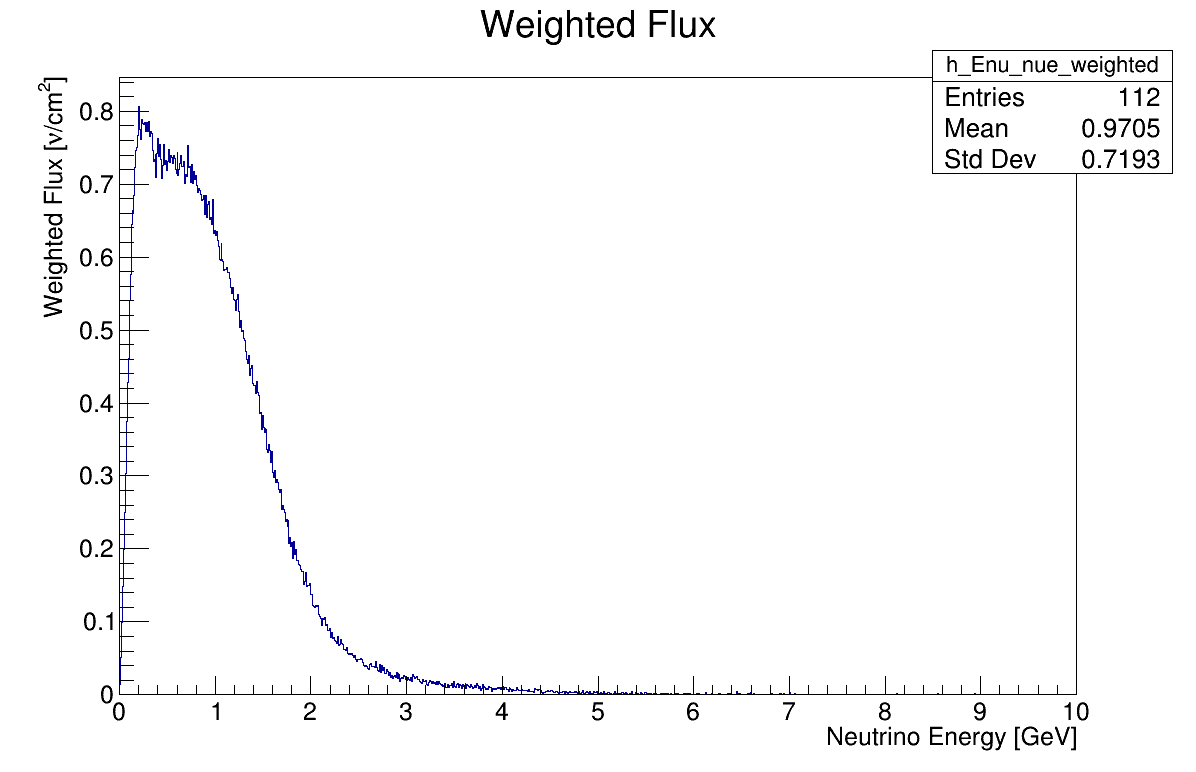

In [7]:
c1 = r.TCanvas("C1", "C1", 1200, 800)
h.SetTitle("Weighted Flux;Neutrino Energy [GeV];Weighted Flux [#nu/cm^{2}]")
h.Draw()
c1.Draw()

In [12]:
fin = uproot.open('/exp/icarus/app/users/micarrig/BuildEventGenerators/samples/out_0.flat.root:FlatTree_VARS')
fin.keys()

['Mode',
 'ResCode',
 'PDGnu',
 'Enu_true',
 'Nleptons',
 'MLep',
 'ELep',
 'TLep',
 'CosLep',
 'CosPmuPpip',
 'CosPmuPpim',
 'CosPmuPpi0',
 'CosPmuPprot',
 'CosPmuPneut',
 'Nprotons',
 'MPr',
 'EPr',
 'TPr',
 'CosPr',
 'CosPprotPneut',
 'Nneutrons',
 'MNe',
 'ENe',
 'TNe',
 'CosNe',
 'Npiplus',
 'MPiP',
 'EPiP',
 'TPiP',
 'CosPiP',
 'CosPpipPprot',
 'CosPpipPneut',
 'CosPpipPpim',
 'CosPpipPpi0',
 'Npineg',
 'MPiN',
 'EPiN',
 'TPiN',
 'CosPiN',
 'CosPpimPprot',
 'CosPpimPneut',
 'CosPpimPpi0',
 'Npi0',
 'MPi0',
 'EPi0',
 'TPi0',
 'CosPi0',
 'CosPi0Pprot',
 'CosPi0Pneut',
 'Nother',
 'Q2_true',
 'q0_true',
 'q3_true',
 'Emiss',
 'pmiss',
 'Emiss_preFSI',
 'pmiss_preFSI',
 'Enu_QE',
 'Q2_QE',
 'W_nuc_rest',
 'bjorken_x',
 'bjorken_y',
 'Erecoil_true',
 'Erecoil_charged',
 'Erecoil_minerva',
 'nu_4mom',
 'pmu_4mom',
 'hm_ppip_4mom',
 'hm_ppim_4mom',
 'hm_ppi0_4mom',
 'hm_pprot_4mom',
 'hm_pneut_4mom',
 'Weight',
 'InputWeight',
 'RWWeight',
 'FluxWeight',
 'fScaleFactor',
 'flagCCINC',
 

Warning in <TROOT::Append>: Replacing existing TH1: h (Potential memory leak).


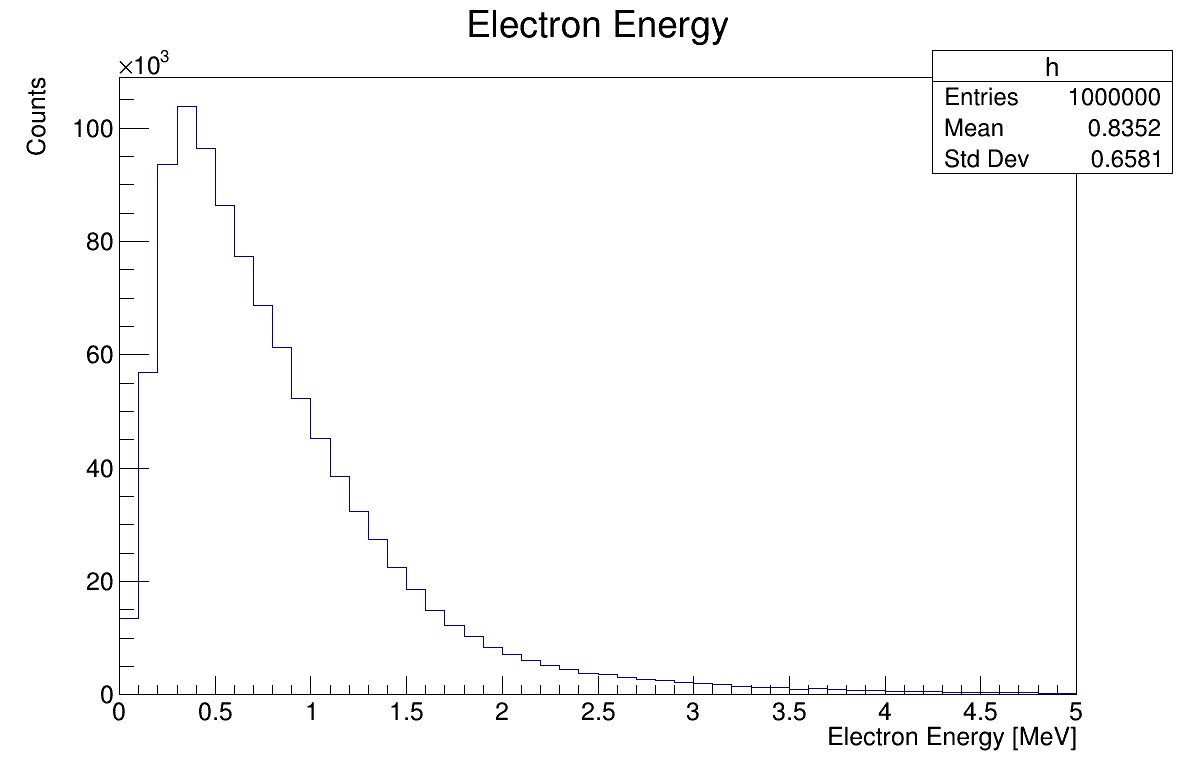

In [14]:
arr_eleE = fin['ICARUS_1eInc_electronEnergy'].array(library="np")

a_eleE = array.array('d', arr_eleE)

h = r.TH1D("h", "Electron Energy;Electron Energy [MeV];Counts", 50, 0, 5)

h.FillN(len(a_eleE), a_eleE, array.array('d', [1.0] * len(a_eleE)))

c1.Clear()

h.Draw()

c1.Draw()